# Constrained GCN-LSTM-PPO for Amazon Last-Mile Routing

Run the cells **top to bottom**. After a disconnect, re-run all cells: finished stages are skipped and training resumes from its last checkpoint.

- `dev` preset: 300 routes, 1 seed. Quick end-to-end check.
- `full` preset: all routes, 3 seeds, penalty sweep. Use for paper numbers.
- Split: `stratified` keeps the station x route-size mix equal in train/val/test.
- Speed: routes are rolled out in batches and kept in memory after the first read; results are mathematically unchanged.
- Two accounts: give each a different `SEEDS` and the same cache folder. When both finish, copy machine B's `runs_<preset>_<split>/*_s2` folders and `gate_stage3_s2.json` into machine A's runs folder and re-run the pipeline with `SEEDS = None`: everything is skipped except the combined report.
- v3 behaviour goals: a `pass_by` constraint (never drive past an unserved stop and come back for it), local time of day from each route's departure time, and per-route "no worse than the driver" shares in the report. An older cache is upgraded automatically (adds `route_meta.json`, no re-prepare).
- v4: every model is also reported as `<name>+zls` (policy + zone-preserving 2-opt: never slower, same zone order); learning-rate 1e-3 variants; Pareto sweep on the first seed only; `WORKERS = 2` trains two seeds at once. While running, each seed's progress is printed every 2 minutes; full logs are in `runs_*/pipeline_seed<s>.log`.
- v4.1 (same results as v4, safe to switch mid-run): cost-only replays, each route built once per worker, live worker status lines, no BC warning spam.
- v5 (best of both worlds): (1) every key model is also evaluated as best of 64 sampled routes, choosing either the fastest or the lowest penalised cost (travel time + the model's own learned penalties; no driver data of the evaluated route); (2) a resumable stage solves every route with zone-aware OR-Tools (~30 min), used as a new baseline and as a teacher; (3) two new learned-constraint models per seed are taught by better routes: the driver's zone order re-sorted inside zones, and zone-aware OR-Tools. Keep WORK_DIR on lastmile_work_v4: the 22 finished models are reused. Then run make_paper_results.py for the figures and table.

## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


## 2. Settings

In [ ]:
# Folder containing eval_route_data.json, eval_travel_times.json, eval_actual_sequences.json (searched recursively)
DATA_ROOT = "/content/drive/MyDrive/amazon_dataset"

# "dev" = quick check, "full" = paper results
PRESET = "full"

# "stratified" = station x route-size mix kept equal in every split (default)
# "station"    = whole stations held out for val/test (tests generalisation to new areas)
# "route"      = plain random split (old behaviour)
SPLIT_BY = "stratified"

# Results of this code version go here (v4 = v3 + local search, lr variants, parallel seeds; models differ from v2,
# so runs must not be mixed). OLD_WORK_DIR is only read, to reuse its prepared cache.
WORK_DIR = "/content/drive/MyDrive/lastmile_work_v4"
OLD_WORK_DIR = "/content/drive/MyDrive/lastmile_work"

# Seeds run on THIS machine. None = all seeds of the preset.
# Sharing one full run between two Colab accounts: machine A uses SEEDS = [0, 1], machine B SEEDS = [2].
# Both must use the same prepared cache folder (copy cache_<preset>_<split> from A to B before starting).
SEEDS = None
SEEDS_ARG = "" if SEEDS is None else "--seeds " + " ".join(map(str, SEEDS))

# Seeds trained at the same time on this machine (separate processes; results identical to sequential).
# 2 suits Colab's free T4 (2 CPU cores). Use 1 if Colab runs out of RAM.
WORKERS = 2

# GPU when Colab gives one, otherwise CPU (e.g. after the free GPU quota runs out): the run continues
# either way. Mixing devices within one run is valid but not bit-reproducible.
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cuda


### Reuse the prepared cache (optional, saves the `prepare` stage)
Copies validated routes, splits and baselines (incl. OR-Tools) from `OLD_WORK_DIR`. The cache format is unchanged; training and evaluation are recomputed with this code version.

In [ ]:
import os, shutil
tag = f"{PRESET}_{SPLIT_BY}"
src, dst = f"{OLD_WORK_DIR}/cache_{tag}", f"{WORK_DIR}/cache_{tag}"
if os.path.exists(f"{src}/index.json") and not os.path.exists(dst):
    shutil.copytree(src, dst)
    print("reused cache:", src, "->", dst)
else:
    print("nothing to copy (no prepared cache in OLD_WORK_DIR, or already copied)")

nothing to copy (no prepared cache in OLD_WORK_DIR, or already copied)


## 3. Write the script
This cell saves `lastmile_rl.py` to the Colab runtime. It must run as a separate process (`!python`), not via `%run` or `import`, because OR-Tools has to load before torch.

In [ ]:
%%writefile /content/lastmile_rl.py
"""
lastmile_rl.py - Constrained GCN-LSTM-PPO for the Amazon Last-Mile Routing dataset.

COLAB: the only input is the dataset path.

  from google.colab import drive; drive.mount('/content/drive')
  !python /content/drive/MyDrive/lastmile_rl.py pipeline --data-root "/content/drive/MyDrive/amazon_dataset"

  * --data-root may be any folder that contains the three eval_*.json files (searched recursively).
  * Outputs go to /content/drive/MyDrive/lastmile_work/ (cache, runs, report). Re-run the same cell
    after a disconnect: finished steps are skipped, training resumes from its last checkpoint.
  * Default --preset dev (300 routes, 1 seed) proves the pipeline end to end. For paper numbers
    run the same command with --preset full (all routes, 3 seeds, penalty sweep for the Pareto plot).
  * Run it with !python (a fresh process), not %run or import: OR-Tools must load before torch.
  * Speed: --workers 2 trains two seeds at once in separate processes (results identical to running them
    one after another); the Pareto penalty sweep runs on the preset's first seed only (--sweep-all-seeds
    restores it for every seed).
  * Teachers for behaviour cloning (--teacher): "driver" (the recorded route), "driver_zls" (the driver's zone
    order, stops re-sorted inside each zone by 2-opt, kept only if no behaviour cost exceeds the driver's) and
    "zone_ortools" (OR-Tools with a fixed cost per zone switch). The driver's own route always sets the budgets.
    zone_ortools is also reported as an evaluation baseline ("zone-aware OR-Tools").
  * Sampling (evaluate --samples K): besides the greedy route, K-1 routes are sampled from the policy and two
    are kept per route: the fastest ("<name>+sK fast") and the one with the lowest penalised cost, i.e. travel
    time plus the model's own learned penalties ("<name>+sK"). Only planning information is used: no driver
    data of the evaluated route.
  * Every trained model is evaluated twice from one rollout: the pure policy (<name>) and the policy plus
    zone-preserving 2-opt (<name>+zls; never slower, zone order and re-entries unchanged, kept per route only
    if no behaviour cost gets worse).
  * Results: lastmile_work/report_<preset>_<split>/test/report.md, pareto.png; test_perturb/report.md.
  * Split: --split-by stratified (default) keeps the station x route-size mix equal in train/val/test.
    Also available: route (plain random) and station (whole stations held out, tests generalisation).
    Each (preset, split) pair gets its own cache/runs/report folders, so results never overwrite.

One file, one code path for training and evaluation. Subcommands map to the workflow:

  pipeline  all stages below in order, with skip/resume and the Stage-3 gate

  prepare   Stage 1   validate routes, cache matrices, train/val/test split, baselines
                      (driver, nearest-neighbour, NN+2-opt, OR-Tools)
  verify    Stage 2   environment correctness checks (exits non-zero on failure)
  bc        Stage 3a  behaviour cloning on driver sequences (warm start)
  train     Stage 3b  PPO with frozen penalties  (--penalty frozen)      = current system
            Stage 4   PPO-Lagrangian, driver-calibrated budgets (--penalty lagrangian)
  evaluate  Stage 6   greedy policy or random-within-mask on a split (+ travel-time perturbation)
  report    Stage 6   aggregate evals across seeds, paired Wilcoxon tests, Pareto plot

Manual sequence (what `pipeline` runs for you):

  python lastmile_rl.py prepare  --data-root /content/drive/MyDrive/amazon_dataset --max-routes 300
  python lastmile_rl.py verify   --mask topk
  python lastmile_rl.py verify   --mask free
  python lastmile_rl.py evaluate --random --mask topk --split val
  python lastmile_rl.py bc       --name bc_topk --mask topk
  python lastmile_rl.py train    --name frozen_topk --mask topk --penalty frozen \
                                 --init runs/bc_topk_s0/best.pt
  python lastmile_rl.py evaluate --ckpt runs/frozen_topk_s0/best.pt --split val
  python lastmile_rl.py train    --name lagr_free_p3 --mask free --phases 3 --penalty lagrangian \
                                 --init runs/bc_topk_s0/best.pt
  python lastmile_rl.py evaluate --ckpt runs/lagr_free_p3_s0/best.pt --split test
  python lastmile_rl.py report   --evals "runs/*/eval_test.json" --reference frozen_topk

Conventions
  * Tours are open paths: station -> all stops, no return leg (paper Eq. 1).
  * All times are seconds internally; reports show minutes.
  * Costs per step: zone_exit (0..1, scaled by stops left behind, capped at 5),
    zone_reentry (0/1, entering a zone previously left with stops remaining),
    far_jump (0/1, regret over the nearest unvisited stop > --farjump-regret seconds),
    pass_by (0..1, unvisited stops skipped although they lay on the way: w is on the way from u to v when
    T(u,w) + T(w,v) <= (1 + --passby-slack) * T(u,v); scaled by the number skipped, capped at 5).
    pass_by is the "drive past a stop and come back for it later" pattern, e.g. visiting B, A, C when
    A, B, C lie along one road.
  * Time of day: each route's real departure time (date_YYYY_MM_DD + departure_time_utc, converted to
    the station's local time) plus elapsed travel time is given to the LSTM as sin/cos of the local hour.
    The dataset has one static travel-time matrix per route: no traffic by hour exists in it, so time of
    day can only be learned from how drivers behave at different hours.
  * Driver budgets: the same costs measured by replaying the driver's actual sequence.
  * amazon_score: the challenge's route score (SeqDev x ERP-per-edit on the z-normalized matrix),
    reimplemented from the definitions in MIT-CAVE/rc-cli scoring/score.py and checked to give
    identical values. Lower = closer to the driver; the driver itself scores 0.
  * Determinism is guaranteed on CPU (default device). On CUDA, results may vary slightly.
  * Speed: routes are rolled out in lockstep (one batched forward pass per decision step for all
    routes of a PPO update, validation or evaluation chunk); every route is cached in memory after its
    first read; the actor's shared r_t half is computed once per step. PPO/BC keep one unpadded
    forward/backward pass per episode. The maths is unchanged; only the random-number stream of
    sampling differs from the earlier one-route-at-a-time version, so runs started with that
    version should be finished with it (or restarted) rather than resumed with this one.

Dependencies: numpy, torch (preinstalled on Colab); ijson, ortools, scipy, matplotlib are
installed automatically when missing (set LASTMILE_NO_AUTOINSTALL=1 to disable).
"""

from __future__ import annotations

import argparse
import glob
import json
import os
import random
import sys
import time
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np


def _ensure_packages() -> None:
    """Install missing pip dependencies before torch is imported (OR-Tools must load first)."""
    import importlib.util
    import subprocess

    wanted = {"ijson": "ijson>=3.1", "ortools": "ortools", "scipy": "scipy", "matplotlib": "matplotlib"}
    missing = [pip for mod, pip in wanted.items() if importlib.util.find_spec(mod) is None]
    if missing and os.environ.get("LASTMILE_NO_AUTOINSTALL") != "1":
        print(f"Installing missing packages: {missing}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


_ensure_packages()

try:  # must be imported before torch: both bundle abseil/protobuf and segfault in the other order
    from ortools.constraint_solver import pywrapcp, routing_enums_pb2
except ImportError:
    pywrapcp = routing_enums_pb2 = None

import torch
import torch.nn as nn
import torch.nn.functional as F

COST_NAMES = ("zone_exit", "zone_reentry", "far_jump", "pass_by")
K_COSTS = len(COST_NAMES)
BASELINE_NAMES = ("driver", "nn", "nn_2opt", "ortools", "zone_ortools")
MASKED_LOGIT = -1e9


# =====================================================================================
# Utilities
# =====================================================================================

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def write_json(path: Path, obj) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)


def score_sequence(seq, T: np.ndarray) -> float:
    s = np.asarray(seq, dtype=np.int64)
    return float(T[s[:-1], s[1:]].astype(np.float64).sum())


def normalized_matrix(T: np.ndarray) -> np.ndarray:
    z = (T - T.mean()) / T.std()
    return z - z.min()


def amazon_score(sub: list[int], actual: list[int], Mn: np.ndarray, g: float = 1000.0) -> float:
    """Challenge route score. sub/actual: closed tours (station at both ends), Mn: normalized_matrix(T)."""
    a_in = list(actual[1:-1])
    n = len(a_in)
    pos = {v: i for i, v in enumerate(a_in)}
    comp = np.array([pos[v] for v in sub[1:-1]])
    seq_dev = (2.0 / (n * (n - 1))) * float((np.abs(np.diff(comp)) - 1).sum())
    La, Ls = len(actual), len(sub)
    D = [[0.0] * (Ls + 1) for _ in range(La + 1)]   # ERP over suffixes actual[i:], sub[j:]
    C = [[0] * (Ls + 1) for _ in range(La + 1)]     # number of edits on the chosen path
    for j in range(Ls + 1):
        D[La][j], C[La][j] = g * (Ls - j), Ls - j
    for i in range(La + 1):
        D[i][Ls], C[i][Ls] = g * (La - i), La - i
    for i in range(La - 1, -1, -1):
        ai, Mrow, Dn, Cn, Di, Ci = actual[i], Mn[actual[i]], D[i + 1], C[i + 1], D[i], C[i]
        for j in range(Ls - 1, -1, -1):
            o1 = Dn[j + 1] + Mrow[sub[j]]
            o2 = Dn[j] + g
            o3 = Di[j + 1] + g
            d = min(o1, o2, o3)
            if d == o1:                     # same tie-breaking order as the official scorer
                c = Cn[j + 1] + (0 if ai == sub[j] else 1)
            elif d == o2:
                c = Cn[j] + 1
            else:
                c = Ci[j + 1] + 1
            Di[j], Ci[j] = d, c
    erp_per_edit = D[0][0] / C[0][0] if C[0][0] else 0.0
    return seq_dev * erp_per_edit


def amazon_route_score(seq, driver, T: np.ndarray) -> float:
    st = int(seq[0])
    return amazon_score([int(x) for x in seq] + [st], [int(x) for x in driver] + [st], normalized_matrix(T))


# The five metro areas of the Amazon Last-Mile Routing Research Challenge, keyed by station-code prefix.
STATION_TZ = {"DLA": "America/Los_Angeles", "DSE": "America/Los_Angeles", "DCH": "America/Chicago",
              "DAU": "America/Chicago", "DBO": "America/New_York"}


def departure_meta(routes: dict, ids: list[str]) -> tuple[dict, dict]:
    """Local departure hour per route from date_YYYY_MM_DD + departure_time_utc and the station's time zone."""
    from datetime import datetime, timezone
    from zoneinfo import ZoneInfo

    meta, notes = {}, Counter()
    for rid in ids:
        r = routes[rid]
        d, t = r.get("date_YYYY_MM_DD"), r.get("departure_time_utc")
        if not d or not t:
            raise SystemExit(f"Route {rid} has no date_YYYY_MM_DD / departure_time_utc; its keys: {sorted(r)}")
        when = datetime.fromisoformat(f"{d}T{t}").replace(tzinfo=timezone.utc)
        tz = STATION_TZ.get(str(r.get("station_code", ""))[:3])
        if tz is None:
            notes["station_time_zone_unknown_used_utc"] += 1
        else:
            when = when.astimezone(ZoneInfo(tz))
        meta[rid] = {"departure_local_hour": when.hour + when.minute / 60 + when.second / 3600,
                     "time_zone": tz or "UTC"}
    return meta, dict(notes)


def write_route_meta(cache: Path, routes_json: Path, ids: list[str]) -> None:
    meta, notes = departure_meta(load_json(routes_json), ids)
    write_json(cache / "route_meta.json", {"routes": meta, "notes": notes})
    print(f"route_meta.json: departure times for {len(meta)} routes; notes: {notes or 'none'}")


def make_run_dir(runs_dir: str, name: str, seed: int, overwrite: bool) -> Path:
    run_dir = Path(runs_dir) / f"{name}_s{seed}"
    if run_dir.exists() and any(run_dir.iterdir()) and not overwrite:
        raise SystemExit(f"{run_dir} already exists; pass --overwrite or use a new --name.")
    run_dir.mkdir(parents=True, exist_ok=True)
    return run_dir


# =====================================================================================
# Baseline solvers
# =====================================================================================

def nearest_neighbor(T: np.ndarray, start: int) -> list[int]:
    n = T.shape[0]
    visited = np.zeros(n, dtype=bool)
    visited[start] = True
    seq = [start]
    cur = start
    for _ in range(n - 1):
        row = np.where(visited, np.inf, T[cur])
        cur = int(np.argmin(row))
        visited[cur] = True
        seq.append(cur)
    return seq


def two_opt(seq: list[int], T: np.ndarray, max_rounds: int, fixed_end: bool = False) -> list[int]:
    """Best-improvement 2-opt on a path with fixed start (and fixed end if asked); exact for asymmetric T."""
    s = np.asarray(seq, dtype=np.int64).copy()
    n = len(s)
    last = n - 2 if fixed_end else n - 1        # highest position a reversed segment may reach
    for _ in range(max_rounds):
        improved = False
        for i in range(1, last):
            fwd = T[s[:-1], s[1:]].astype(np.float64)
            bwd = T[s[1:], s[:-1]].astype(np.float64)
            cf = np.concatenate([[0.0], np.cumsum(fwd)])
            cb = np.concatenate([[0.0], np.cumsum(bwd)])
            j = np.arange(i + 1, last + 1)
            nxt = s[np.minimum(j + 1, n - 1)]
            has_next = j < n - 1
            old = T[s[i - 1], s[i]] + (cf[j] - cf[i]) + np.where(has_next, T[s[j], nxt], 0.0)
            new = T[s[i - 1], s[j]] + (cb[j] - cb[i]) + np.where(has_next, T[s[i], nxt], 0.0)
            delta = new - old
            k = int(np.argmin(delta))
            if delta[k] < -1e-6:
                jj = int(j[k])
                s[i:jj + 1] = s[i:jj + 1][::-1].copy()
                improved = True
        if not improved:
            break
    return s.tolist()


def zone_local_search(seq: list[int], zone: np.ndarray, T: np.ndarray, max_rounds: int = 50) -> list[int]:
    """2-opt inside each block of consecutive same-zone stops, holding the stop before and after the block fixed.

    The order of zone blocks is untouched, so zone exits and re-entries are identical, and only improving
    moves are applied, so travel time never increases.
    """
    out = list(seq)
    i = 1
    while i < len(out):
        j = i
        while j + 1 < len(out) and zone[out[j + 1]] == zone[out[i]]:
            j += 1
        has_next = j + 1 < len(out)
        path = out[i - 1: j + 2] if has_next else out[i - 1: j + 1]
        if j > i and len(path) >= (4 if has_next else 3):
            order = two_opt(list(range(len(path))), T[np.ix_(path, path)], max_rounds, fixed_end=has_next)
            out[i - 1: i - 1 + len(path)] = [path[k] for k in order]
        i = j + 1
    return out


def ortools_sequence(T: np.ndarray, start: int, seconds: int) -> list[int]:
    return _solve_open_path(T.astype(np.float64), start, seconds)


def zone_ortools_sequence(T: np.ndarray, zone: np.ndarray, start: int, seconds: int, switch_s: float) -> list[int]:
    """OR-Tools with switch_s seconds added to every move between two different zones: fast routes that keep
    each zone together (stops without a zone are free to visit)."""
    switch = (zone[:, None] != zone[None, :]) & (zone[:, None] >= 0) & (zone[None, :] >= 0)
    return _solve_open_path(T.astype(np.float64) + switch * switch_s, start, seconds)


def _solve_open_path(costs: np.ndarray, start: int, seconds: int) -> list[int]:
    """Guided-local-search OR-Tools on an open path from `start` (costs in seconds, solved in deciseconds)."""
    n = costs.shape[0]
    end = n  # dummy end node: zero cost from every node -> open path
    cost = np.zeros((n + 1, n + 1), dtype=np.int64)
    cost[:n, :n] = np.rint(costs * 10.0).astype(np.int64)
    manager = pywrapcp.RoutingIndexManager(n + 1, 1, [start], [end])
    routing = pywrapcp.RoutingModel(manager)

    def transit(i, j):
        return int(cost[manager.IndexToNode(i), manager.IndexToNode(j)])

    cb = routing.RegisterTransitCallback(transit)
    routing.SetArcCostEvaluatorOfAllVehicles(cb)
    params = pywrapcp.DefaultRoutingSearchParameters()
    params.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    params.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    params.time_limit.FromSeconds(int(seconds))
    solution = routing.SolveWithParameters(params)
    if solution is None:
        raise RuntimeError("OR-Tools found no solution")
    seq, idx = [], routing.Start(0)
    while not routing.IsEnd(idx):
        seq.append(manager.IndexToNode(idx))
        idx = solution.Value(routing.NextVar(idx))
    return seq


# =====================================================================================
# Stage 1 - prepare
# =====================================================================================

DATASET_FILES = {"routes": "eval_route_data.json", "travel": "eval_travel_times.json",
                 "sequences": "eval_actual_sequences.json"}


def dataset_files(root: Path) -> dict[str, Path]:
    """Locate the three evaluation files anywhere under `root` (download layouts differ)."""
    if not root.exists():
        raise SystemExit(f"Dataset path not found: {root}")
    hits = defaultdict(list)
    for dirpath, _, files in os.walk(root):
        for key, name in DATASET_FILES.items():
            if name in files:
                hits[key].append(Path(dirpath) / name)
    problems = [f"{name}: not found under {root}" for key, name in DATASET_FILES.items() if not hits[key]]
    problems += [f"{DATASET_FILES[k]}: {len(v)} copies found, keep one: {[str(x) for x in v]}"
                 for k, v in hits.items() if len(v) > 1]
    if problems:
        raise SystemExit("Dataset problem:\n  " + "\n  ".join(problems))
    return {k: v[0] for k, v in hits.items()}


def inspect_route(r: dict, seq: dict | None, a) -> tuple[dict | None, str]:
    if seq is None or "actual" not in seq:
        return None, "no_actual_sequence"
    if a.quality != "any" and r.get("route_score") != a.quality:
        return None, "quality_filtered"
    stops = r["stops"]
    node_ids = list(stops)
    n_deliv = len(node_ids) - 1
    if not (a.min_stops <= n_deliv <= a.max_stops):
        return None, "size_filtered"
    stations = [s for s in node_ids if str(stops[s].get("type", "")).lower() == "station"]
    if len(stations) != 1:
        return None, "station_count_not_1"
    actual = seq["actual"]
    if set(actual) != set(node_ids):
        return None, "sequence_stop_mismatch"
    if len(set(actual.values())) != len(node_ids):
        return None, "sequence_order_duplicates"
    order = sorted(node_ids, key=lambda s: actual[s])
    if order[0] != stations[0]:
        return None, "sequence_not_starting_at_station"
    idx = {s: i for i, s in enumerate(node_ids)}
    zones = []
    for s in node_ids:
        z = stops[s].get("zone_id")
        zones.append(z if (isinstance(z, str) and z and s != stations[0]) else "")
    return {
        "node_ids": node_ids,
        "station": idx[stations[0]],
        "driver": [idx[s] for s in order],
        "lat": [float(stops[s]["lat"]) for s in node_ids],
        "lng": [float(stops[s]["lng"]) for s in node_ids],
        "zones": zones,
        "is_dropoff": [str(stops[s].get("type", "")).lower() == "dropoff" for s in node_ids],
        "station_code": str(r.get("station_code", "")),
    }, "ok"


MIN_STRATUM = 6   # strata smaller than this are pooled by size bin only (15% of fewer than 6 rounds to 0)


def size_bins(ids: list[str], metas: dict) -> dict[str, int]:
    """Quartile bin (0..3) of the number of delivery stops, computed over the selected routes."""
    sizes = np.array([len(metas[r]["node_ids"]) - 1 for r in ids])
    edges = np.quantile(sizes, [0.25, 0.5, 0.75])
    return {r: int(np.searchsorted(edges, s, side="right")) for r, s in zip(ids, sizes)}


def stratified_splits(ids: list[str], metas: dict, a, rng: random.Random) -> dict[str, list[str]]:
    """Train/val/test split that keeps the station x route-size mix the same in every split.

    Stratum = (station_code, size quartile). Strata with fewer than MIN_STRATUM routes are pooled
    by size quartile alone so rare stations still contribute and fractions stay close to the targets.
    """
    bins = size_bins(ids, metas)
    strata = defaultdict(list)
    for rid in sorted(ids):
        strata[(metas[rid]["station_code"], bins[rid])].append(rid)
    pooled = defaultdict(list)
    for key in sorted(strata):
        if len(strata[key]) < MIN_STRATUM:
            pooled[("*", key[1])] += strata.pop(key)
    strata.update(pooled)
    splits = {"test": [], "val": [], "train": []}
    for key in sorted(strata):
        grp = strata[key]
        rng.shuffle(grp)
        n_t, n_v = int(round(len(grp) * a.test_frac)), int(round(len(grp) * a.val_frac))
        splits["test"] += grp[:n_t]
        splits["val"] += grp[n_t:n_t + n_v]
        splits["train"] += grp[n_t + n_v:]
    return splits


def print_split_summary(splits: dict[str, list[str]], metas: dict, ids: list[str]) -> dict:
    """Print and return per-split balance (routes, stations, mean stops, size-quartile mix)."""
    bins = size_bins(ids, metas)
    out = {}
    print(f"{'split':<6}{'routes':>8}{'stations':>10}{'mean_stops':>12}   size quartiles (Q1..Q4)")
    for name in ("train", "val", "test"):
        lst = splits[name]
        if not lst:
            out[name] = {"routes": 0}
            continue
        stops = [len(metas[r]["node_ids"]) - 1 for r in lst]
        stations = {metas[r]["station_code"] for r in lst}
        mix = [sum(1 for r in lst if bins[r] == b) / len(lst) for b in range(4)]
        out[name] = {"routes": len(lst), "stations": len(stations), "mean_stops": float(np.mean(stops)),
                     "size_quartile_mix": mix}
        print(f"{name:<6}{len(lst):>8}{len(stations):>10}{np.mean(stops):>12.1f}   "
              + " ".join(f"{m:.2f}" for m in mix))
    overlap = {s: len({metas[r]['station_code'] for r in splits[s]} &
                      {metas[r]['station_code'] for r in splits['train']}) for s in ("val", "test") if splits[s]}
    print(f"stations shared with train: {overlap}")
    return out


def make_splits(ids: list[str], metas: dict, a) -> dict[str, list[str]]:
    rng = random.Random(a.seed)
    n = len(ids)
    n_test, n_val = int(round(n * a.test_frac)), int(round(n * a.val_frac))
    if a.split_by == "route":
        return {"test": ids[:n_test], "val": ids[n_test:n_test + n_val], "train": ids[n_test + n_val:]}
    if a.split_by == "stratified":
        return stratified_splits(ids, metas, a, rng)
    groups = defaultdict(list)
    for rid in ids:
        groups[metas[rid]["station_code"]].append(rid)
    stations = sorted(groups)
    rng.shuffle(stations)
    splits = {"test": [], "val": [], "train": []}
    for st in stations:
        if len(splits["test"]) < n_test:
            splits["test"] += groups[st]
        elif len(splits["val"]) < n_val:
            splits["val"] += groups[st]
        else:
            splits["train"] += groups[st]
    return splits


def build_matrix(node_ids: list[str], mat: dict) -> np.ndarray | None:
    """Full float64 matrix including the diagonal, exactly as the official scorer reads it."""
    n = len(node_ids)
    T = np.zeros((n, n), dtype=np.float64)
    for i, o in enumerate(node_ids):
        row = mat.get(o)
        if row is None:
            return None
        for j, d in enumerate(node_ids):
            v = row.get(d)
            if v is None:
                return None
            T[i, j] = float(v)
    return T


def cmd_prepare(a) -> None:
    import ijson

    files = dataset_files(Path(a.data_root))
    for k, path in files.items():
        print(f"{k:<10} {path}")
    cache = Path(a.cache_dir)
    if (cache / "index.json").exists() and not a.overwrite:
        raise SystemExit(f"{cache} already prepared; pass --overwrite to rebuild.")
    (cache / "routes").mkdir(parents=True, exist_ok=True)
    if a.ortools_seconds > 0 and pywrapcp is None:
        raise SystemExit("OR-Tools not installed: pip install ortools, or pass --ortools-seconds 0.")

    print("Loading route data and actual sequences...")
    routes = load_json(files["routes"])
    seqs = load_json(files["sequences"])
    has_score = any("route_score" in r for r in routes.values())
    if a.quality != "any" and not has_score:
        raise SystemExit("--quality set but route data has no 'route_score' field.")

    skipped: Counter = Counter()
    metas = {}
    for rid in sorted(routes):
        meta, reason = inspect_route(routes[rid], seqs.get(rid), a)
        if meta is None:
            skipped[reason] += 1
        else:
            metas[rid] = meta
    ids = sorted(metas)
    random.Random(a.seed).shuffle(ids)
    if a.max_routes:
        ids = ids[:a.max_routes]
    wanted = set(ids)
    print(f"Valid routes: {len(metas)}  selected: {len(ids)}  skipped: {dict(skipped)}")

    print("Streaming travel-time matrices (one pass)...")
    cached = set()
    with open(files["travel"], "rb") as f:
        for rid, mat in ijson.kvitems(f, "", use_float=True):
            if rid not in wanted:
                continue
            m = metas[rid]
            T = build_matrix(m["node_ids"], mat)
            if T is None:
                skipped["travel_matrix_incomplete"] += 1
            else:
                np.savez_compressed(
                    cache / "routes" / f"{rid}.npz",
                    T=T, lat=np.array(m["lat"]), lng=np.array(m["lng"]),
                    zones=np.array(m["zones"]), is_dropoff=np.array(m["is_dropoff"]),
                    station=np.int64(m["station"]), driver=np.array(m["driver"], dtype=np.int64),
                    node_ids=np.array(m["node_ids"]), station_code=np.array(m["station_code"]),
                )
                cached.add(rid)
            if len(cached) + skipped["travel_matrix_incomplete"] == len(wanted):
                break
    skipped["no_travel_matrix"] += len(wanted) - len(cached) - skipped["travel_matrix_incomplete"]
    ids = [rid for rid in ids if rid in cached]
    splits = make_splits(ids, metas, a)
    print(f"split mode: {a.split_by}")
    split_summary = print_split_summary(splits, metas, ids)

    print("Computing baselines...")
    split_of = {rid: s for s, lst in splits.items() for rid in lst}
    baselines = {}
    for i, rid in enumerate(ids, 1):
        z = np.load(cache / "routes" / f"{rid}.npz")
        T, st, drv = z["T"], int(z["station"]), z["driver"].tolist()
        nn_seq = nearest_neighbor(T, st)
        b = {"driver": {"seq": drv, "time": score_sequence(drv, T)},
             "nn": {"seq": nn_seq, "time": score_sequence(nn_seq, T)}}
        if split_of[rid] != "train":
            opt = two_opt(nn_seq, T, a.two_opt_rounds)
            b["nn_2opt"] = {"seq": opt, "time": score_sequence(opt, T)}
            if a.ortools_seconds > 0:
                ort = ortools_sequence(T, st, a.ortools_seconds)
                b["ortools"] = {"seq": ort, "time": score_sequence(ort, T)}
            for v in b.values():
                v["amazon_score"] = amazon_route_score(v["seq"], drv, T)
        baselines[rid] = b
        if i % 100 == 0 or i == len(ids):
            print(f"  {i}/{len(ids)}")

    write_json(cache / "baselines.json", baselines)
    write_route_meta(cache, files["routes"], ids)
    write_json(cache / "index.json", {
        "created": time.strftime("%Y-%m-%d %H:%M:%S"),
        "args": {k: v for k, v in vars(a).items() if k != "func"},
        "has_route_score": has_score,
        "skipped": dict(skipped),
        "splits": splits,
        "split_summary": split_summary,
    })
    print(f"Prepared {len(ids)} routes in {cache}")


# =====================================================================================
# Teachers: zone-aware OR-Tools for every route (BC teacher on train, baseline on val/test)
# =====================================================================================

def _zone_ortools_job(job: tuple) -> tuple[str, list[int]]:
    rid, cache, seconds, switch_s = job
    with np.load(Path(cache) / "routes" / f"{rid}.npz") as z:
        T, names, station = z["T"], [str(x) for x in z["zones"]], int(z["station"])
    return rid, zone_ortools_sequence(T, zone_ids(names)[0], station, seconds, switch_s)


def cmd_teachers(a) -> None:
    """Solve every route with zone-aware OR-Tools (resumable: progress saved every 100 routes), then add it as
    the "zone_ortools" baseline for validation and test routes."""
    import multiprocessing as mp

    cache = Path(a.cache_dir)
    out = cache / "zone_ortools.json"
    index = load_json(cache / "index.json")
    ids = [r for sp in ("train", "val", "test") for r in index["splits"][sp]]
    done = load_json(out) if out.exists() else {}
    todo = [r for r in ids if r not in done]
    print(f"zone-aware OR-Tools: {len(done)} routes done, {len(todo)} to go "
          f"({a.teacher_seconds} s each, {a.teacher_workers} processes, {a.switch_penalty:g} s per zone switch)")
    if todo:                       # fork before this process touches torch: children only run OR-Tools and numpy
        with mp.get_context("fork").Pool(a.teacher_workers) as pool:
            jobs = [(rid, str(cache), a.teacher_seconds, a.switch_penalty) for rid in todo]
            for i, (rid, seq) in enumerate(pool.imap_unordered(_zone_ortools_job, jobs), 1):
                done[rid] = seq
                if i % 100 == 0 or i == len(todo):
                    write_json(out, done)
                    print(f"  {len(done)}/{len(ids)}", flush=True)
    store = RouteStore(a.cache_dir, EnvConfig(), torch.device("cpu"))
    for rid in [r for sp in ("val", "test") for r in index["splits"][sp]]:
        route = store.get(rid)
        seq = done[rid]
        store.baselines[rid]["zone_ortools"] = {"seq": seq, "time": score_sequence(seq, route.T),
                                                "amazon_score": amazon_route_score(seq, route.driver, route.T)}
    write_json(cache / "baselines.json", store.baselines)
    write_json(cache / "zone_ortools_done.json", {"routes": len(done), "seconds": a.teacher_seconds,
                                                  "switch_penalty_s": a.switch_penalty})
    print(f"-> {out}; zone_ortools baseline added for validation and test routes")


def teacher_sequence(route: "Route", cfg: "EnvConfig", kind: str, zone_ortools: dict | None) -> np.ndarray:
    """The visiting order behaviour cloning imitates on one route."""
    if kind == "driver":
        return route.driver
    if kind == "zone_ortools":
        return np.asarray(zone_ortools[route.rid], dtype=np.int64)
    seq = zone_local_search(list(route.driver), route.zone, route.T)                  # driver_zls
    ok = (replay_costs(route, cfg, seq).sum(0) <= route.budget.sum(0) + 1e-9).all()
    return np.asarray(seq if ok else route.driver, dtype=np.int64)


# =====================================================================================
# Routes, environment, features
# =====================================================================================

@dataclass(frozen=True)
class EnvConfig:
    mask: str = "topk"            # "topk" (top-k nearest UNION current-zone) or "free" (all unvisited)
    top_k: int = 12
    n_phases: int = 1
    farjump_regret_s: float = 300.0
    passby_slack: float = 0.10


@dataclass
class Route:
    rid: str
    T: np.ndarray                 # [N,N] float64 seconds
    zone: np.ndarray              # [N] int, -1 = no zone
    n_zones: int
    station: int
    driver: np.ndarray            # [N] visiting order, driver[0] == station
    tau: float                    # median positive travel time (feature scale)
    X: torch.Tensor               # [N,4] lat, lng, station, dropoff
    stats: torch.Tensor           # [N,4] normalized mean/median/min/max outgoing time
    A: torch.Tensor               # [N,N] normalized travel-time adjacency
    budget: np.ndarray            # [P,K] driver costs per phase
    dep_hour: float               # local departure time of day, hours


def _minmax(v: np.ndarray) -> np.ndarray:
    v = np.nan_to_num(v.astype(np.float64), nan=0.0)
    return (v - v.min()) / (v.max() - v.min() + 1e-8)


def zone_ids(names: list[str]) -> tuple[np.ndarray, int]:
    """Integer zone per stop (-1 = no zone) and the number of zones, in sorted zone-name order."""
    uniq = sorted({s for s in names if s})
    zid = {s: i for i, s in enumerate(uniq)}
    return np.array([zid[s] if s else -1 for s in names], dtype=np.int64), len(uniq)


def build_route(rid: str, z, env_cfg: EnvConfig, device: torch.device, dep_hour: float) -> Route:
    T = z["T"].astype(np.float64)
    n = T.shape[0]
    names = [str(s) for s in z["zones"]]
    zone, n_zones = zone_ids(names)
    station = int(z["station"])
    pos = T[T > 0]
    tau = float(np.median(pos)) if pos.size else 1.0

    A = np.zeros_like(T)
    A[T > 0] = np.exp(-T[T > 0] / tau)
    np.fill_diagonal(A, 1.0)
    d = A.sum(1)
    dinv = np.where(d > 0, d ** -0.5, 0.0)
    A_norm = (dinv[:, None] * A * dinv[None, :]).astype(np.float32)

    station_ind = np.zeros(n, dtype=np.float32)
    station_ind[station] = 1.0
    X = np.stack([_minmax(z["lat"]), _minmax(z["lng"]), station_ind,
                  z["is_dropoff"].astype(np.float32)], 1).astype(np.float32)

    Tn = np.where(T > 0, T, np.nan).astype(np.float64)
    with np.errstate(all="ignore"):
        stats = np.stack([_minmax(np.nanmean(Tn, 1)), _minmax(np.nanmedian(Tn, 1)),
                          _minmax(np.nanmin(Tn, 1)), _minmax(np.nanmax(Tn, 1))], 1).astype(np.float32)

    route = Route(
        rid=rid, T=T, zone=zone, n_zones=n_zones, station=station,
        driver=z["driver"].astype(np.int64), tau=tau,
        X=torch.tensor(X, device=device), stats=torch.tensor(stats, device=device),
        A=torch.tensor(A_norm, device=device),
        budget=np.zeros((env_cfg.n_phases, K_COSTS), dtype=np.float64), dep_hour=float(dep_hour),
    )
    route.budget = replay_costs(route, env_cfg, route.driver)
    return route


_ROUTES: dict = {}     # built routes shared by all commands of this process (see RouteStore.get)


class RouteStore:
    def __init__(self, cache_dir: str, env_cfg: EnvConfig, device: torch.device):
        self.dir = Path(cache_dir)
        if not (self.dir / "index.json").exists():
            raise SystemExit(f"No prepared cache at {self.dir}; run 'prepare' first.")
        self.index = load_json(self.dir / "index.json")
        self.baselines = load_json(self.dir / "baselines.json")
        if not (self.dir / "route_meta.json").exists():
            raise SystemExit(f"{self.dir} has no route_meta.json (cache made before time-of-day features); "
                             "run the pipeline, which adds it without redoing prepare.")
        self.meta = load_json(self.dir / "route_meta.json")["routes"]
        self.env_cfg, self.device = env_cfg, device

    def get(self, rid: str) -> Route:
        """Routes are kept for the whole process and shared by every command it runs (training runs,
        evaluations): each route is read from disk/Drive and built once per budget-relevant setting.
        About 0.3 MB host + 0.1 MB device memory per 150-stop route and setting."""
        c = self.env_cfg
        key = (str(self.dir.resolve()), rid, c.n_phases, c.farjump_regret_s, c.passby_slack, str(self.device))
        if key not in _ROUTES:
            _ROUTES[key] = self._load(rid)
        return _ROUTES[key]

    def split(self, name: str) -> list[str]:
        if name == "all":
            return [r for s in ("train", "val", "test") for r in self.index["splits"][s]]
        return list(self.index["splits"][name])

    def _load(self, rid: str) -> Route:
        with np.load(self.dir / "routes" / f"{rid}.npz") as z:
            return build_route(rid, z, self.env_cfg, self.device, self.meta[rid]["departure_local_hour"])


class RouteEnv:
    def __init__(self, route: Route, cfg: EnvConfig):
        self.r, self.cfg = route, cfg
        self.N = route.T.shape[0]
        self.n_deliv = self.N - 1
        self.zone_size = np.bincount(route.zone[route.zone >= 0], minlength=route.n_zones)
        self.reset()

    def reset(self) -> None:
        self.visited = np.zeros(self.N, dtype=bool)
        self.visited[self.r.station] = True
        self.cur = self.r.station
        self.completed = 0
        self.total = 0.0
        self.zone_left = self.zone_size.copy()
        self.open_exited: set[int] = set()
        self.seq = [self.r.station]

    @property
    def done(self) -> bool:
        return self.completed == self.n_deliv

    def phase(self) -> int:
        P = self.cfg.n_phases
        return min(P - 1, self.completed * P // self.n_deliv)

    def progress(self) -> np.ndarray:
        """[share delivered, elapsed / (tau * stops), sin and cos of the local time of day]."""
        angle = 2.0 * np.pi * ((self.r.dep_hour + self.total / 3600.0) % 24.0) / 24.0
        return np.array([self.completed / self.n_deliv, self.total / (self.r.tau * self.n_deliv),
                         np.sin(angle), np.cos(angle)], dtype=np.float32)

    def action_mask(self) -> np.ndarray:
        unv = ~self.visited
        if self.cfg.mask == "free":
            return unv
        idx = np.flatnonzero(unv)
        m = np.zeros(self.N, dtype=bool)
        k = self.cfg.top_k
        if idx.size > k:
            m[idx[np.argpartition(self.r.T[self.cur, idx], k - 1)[:k]]] = True
        else:
            m[idx] = True
        zc = self.r.zone[self.cur]
        if zc >= 0:
            m |= unv & (self.r.zone == zc)
        return m

    def step(self, a: int) -> tuple[float, np.ndarray, int]:
        a = int(a)
        if not (0 <= a < self.N) or self.visited[a]:
            raise ValueError(f"illegal action {a} on route {self.r.rid}")
        T, zone, cur = self.r.T, self.r.zone, self.cur
        p = self.phase()
        tt = float(T[cur, a])
        regret = tt - float(T[cur, ~self.visited].min())
        c = np.zeros(K_COSTS, dtype=np.float32)
        cz, tz = int(zone[cur]), int(zone[a])
        if cz >= 0 and tz != cz and self.zone_left[cz] > 0:
            c[0] = min(int(self.zone_left[cz]), 5) / 5.0
            self.open_exited.add(cz)
        if tz >= 0 and tz != cz and tz in self.open_exited:
            c[1] = 1.0
            self.open_exited.discard(tz)
        if regret > self.cfg.farjump_regret_s:
            c[2] = 1.0
        others = ~self.visited
        others[a] = False
        skipped = int((others & (T[cur] + T[:, a] <= (1.0 + self.cfg.passby_slack) * tt)).sum())
        if skipped:
            c[3] = min(skipped, 5) / 5.0
        self.visited[a] = True
        self.cur = a
        self.completed += 1
        self.total += tt
        self.seq.append(a)
        if tz >= 0:
            self.zone_left[tz] -= 1
        return tt, c, p


def replay_costs(route: Route, cfg: EnvConfig, seq) -> np.ndarray:
    """Per-phase costs [P,K] of a fixed visiting order: environment steps only, no features or mask.

    Same numbers as Episode.costs_by_phase of a "follow" rollout (same steps, same float64 summation order).
    """
    env = RouteEnv(route, cfg)
    out = np.zeros((cfg.n_phases, K_COSTS), dtype=np.float64)
    for a in seq[1:]:
        _, c, p = env.step(int(a))
        out[p] += c
    if not env.done:
        raise RuntimeError(f"replayed sequence does not visit every stop of route {route.rid}")
    return out


def dynamic_features(env: RouteEnv) -> np.ndarray:
    """Per-candidate features that depend on the current state: [N,5]."""
    r = env.r
    row = r.T[env.cur].astype(np.float64)
    unv = ~env.visited
    nearest = row[unv].min() if unv.any() else 0.0
    zc = r.zone[env.cur]
    same_zone = (r.zone == zc) & (zc >= 0)
    reentry = np.isin(r.zone, list(env.open_exited)) if env.open_exited else np.zeros(env.N, dtype=bool)
    # unvisited stops on the way to each candidate v (would be skipped by going to v): [w, v] test, w != v
    on_way = (row[:, None] + r.T <= (1.0 + env.cfg.passby_slack) * row[None, :]) & unv[:, None]
    np.fill_diagonal(on_way, False)
    passby = np.minimum(on_way.sum(0), 5) / 5.0
    return np.stack([row / r.tau, np.maximum(row - nearest, 0.0) / r.tau,
                     same_zone, reentry, passby], 1).astype(np.float32)


# =====================================================================================
# Model
# =====================================================================================

class GCN(nn.Module):
    def __init__(self, d_in: int = 4, d_hidden: int = 16, d_out: int = 16):
        super().__init__()
        self.l1, self.l2 = nn.Linear(d_in, d_hidden), nn.Linear(d_hidden, d_out)

    def forward(self, X: torch.Tensor, A: torch.Tensor) -> torch.Tensor:
        return F.relu(self.l2(A @ F.relu(self.l1(A @ X))))


class Policy(nn.Module):
    """GCN node embeddings -> LSTM route context -> candidate-aware actor + critic."""

    GCN_DIM, STATS_DIM, DYN_DIM, PROG_DIM, LSTM_DIM = 16, 4, 5, 4, 32

    def __init__(self, hidden: int = 128):
        super().__init__()
        static_dim = self.GCN_DIM + self.STATS_DIM
        self.gcn = GCN(4, 16, self.GCN_DIM)
        self.lstm = nn.LSTM(static_dim + self.PROG_DIM, self.LSTM_DIM, batch_first=True)
        self.cand = nn.Sequential(nn.Linear(static_dim + self.DYN_DIM, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU())
        self.route = nn.Sequential(nn.Linear(self.LSTM_DIM, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU())
        self.actor = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
        self.critic = nn.Sequential(nn.Linear(self.LSTM_DIM + hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def static(self, route: Route) -> torch.Tensor:
        return torch.cat([self.gcn(route.X, route.A), route.stats], -1)          # [N,20]

    def statics(self, routes: list[Route]) -> torch.Tensor:
        """Static features of several routes, zero-padded to the largest: [B, N_max, 20]."""
        n_max = max(r.T.shape[0] for r in routes)
        out = routes[0].X.new_zeros(len(routes), n_max, self.GCN_DIM + self.STATS_DIM)
        for b, r in enumerate(routes):
            out[b, : r.T.shape[0]] = self.static(r)
        return out

    def heads(self, static, dyn, h, mask, unv):
        # static [S,N,20]  dyn [S,N,4]  h [S,32]  mask/unv [S,N] bool  ->  logits [S,N], value [S]
        c = self.cand(torch.cat([static, dyn], -1))
        r = self.route(h)
        # actor(cat[c, r]) computed exactly but without repeating the r_t half for every stop:
        # W [c; r] + b = W_c c + (W_r r + b), with W_r r + b shared by all stops of a step
        first, last = self.actor[0], self.actor[2]
        hid = c.shape[-1]
        pre = F.linear(c, first.weight[:, :hid]) + F.linear(r, first.weight[:, hid:], first.bias).unsqueeze(1)
        logits = last(F.relu(pre)).squeeze(-1)
        logits = logits.masked_fill(~mask, MASKED_LOGIT)
        w = unv.float().unsqueeze(-1)
        pooled = (c * w).sum(1) / w.sum(1).clamp_min(1.0)
        return logits, self.critic(torch.cat([h, pooled], -1)).squeeze(-1)

    def step(self, static, hc, cur, prog, dyn, mask, unv):
        """One decision for B routes. static [B,N,20], cur [B], prog [B,2], dyn [B,N,4], mask/unv [B,N]."""
        dev = static.device
        rows = torch.arange(static.shape[0], device=dev)
        x = torch.cat([static[rows, torch.as_tensor(cur, device=dev)], torch.as_tensor(prog, device=dev)], -1)
        out, hc = self.lstm(x.unsqueeze(1), hc)
        logits, value = self.heads(static, torch.as_tensor(dyn, device=dev), out[:, 0],
                                   torch.as_tensor(mask, device=dev), torch.as_tensor(unv, device=dev))
        return logits, value, hc

    def evaluate(self, routes: list[Route], eps: list["Episode"]):
        """Forward with gradients over whole trajectories, padded to the longest episode and largest route.

        Returns logits [B,S,N], values [B,S] and the valid-step mask [B,S]. Valid entries equal what
        `step` produced during the rollout (padded nodes are masked, padded steps come after real ones).
        """
        dev = routes[0].X.device
        static = self.statics(routes)
        B, N = static.shape[:2]
        S = max(len(e.actions) for e in eps)
        cur, prog = np.zeros((B, S), np.int64), np.zeros((B, S, self.PROG_DIM), np.float32)
        dyn = np.zeros((B, S, N, self.DYN_DIM), np.float32)
        mask, unv, valid = np.zeros((B, S, N), bool), np.zeros((B, S, N), bool), np.zeros((B, S), bool)
        for b, e in enumerate(eps):
            s, n = e.dyn.shape[:2]
            cur[b, :s], prog[b, :s], dyn[b, :s, :n] = e.cur, e.prog, e.dyn
            mask[b, :s, :n], unv[b, :s, :n], valid[b, :s] = e.mask, e.unv, True
        t = lambda x: torch.as_tensor(x, device=dev)  # noqa: E731
        x = torch.cat([static[torch.arange(B, device=dev)[:, None], t(cur)], t(prog)], -1)     # [B,S,22]
        h, _ = self.lstm(x)
        st = static.unsqueeze(1).expand(B, S, N, static.shape[-1]).reshape(B * S, N, -1)
        logits, values = self.heads(st, t(dyn).reshape(B * S, N, self.DYN_DIM), h.reshape(B * S, -1),
                                    t(mask).reshape(B * S, N), t(unv).reshape(B * S, N))
        return logits.view(B, S, N), values.view(B, S), t(valid)


# =====================================================================================
# Episodes (single code path for sampling, greedy eval, random baseline, replay)
# =====================================================================================

@dataclass
class Episode:
    actions: np.ndarray       # [S]
    cur: np.ndarray           # [S] node before each action
    prog: np.ndarray          # [S,2]
    dyn: np.ndarray           # [S,N,4]
    mask: np.ndarray          # [S,N]
    unv: np.ndarray           # [S,N]
    logp: np.ndarray          # [S]
    values: np.ndarray        # [S]
    travel: np.ndarray        # [S] seconds
    costs: np.ndarray         # [S,K]
    phases: np.ndarray        # [S]
    sequence: list[int]

    @property
    def total_time(self) -> float:
        return float(self.travel.sum())

    def costs_by_phase(self, n_phases: int) -> np.ndarray:
        out = np.zeros((n_phases, K_COSTS), dtype=np.float64)
        np.add.at(out, self.phases, self.costs)
        return out


@torch.no_grad()
def run_episodes(routes: list[Route], cfg: EnvConfig, mode: str, policy: Policy | None = None,
                 rng: np.random.Generator | None = None, follows=None) -> list[Episode]:
    """Roll out several routes in lockstep with one batched forward pass per decision step.

    mode: sample | greedy (need policy) | random (need rng) | follow (fixed action list per route).
    Training, validation, evaluation, baselines and replays all use this one function.
    """
    envs = [RouteEnv(r, cfg) for r in routes]
    B, n_max = len(envs), max(e.N for e in envs)
    eps = [Episode(np.zeros(e.n_deliv, np.int64), np.zeros(e.n_deliv, np.int64),
                   np.zeros((e.n_deliv, Policy.PROG_DIM), np.float32), np.zeros((e.n_deliv, e.N, Policy.DYN_DIM), np.float32),
                   np.zeros((e.n_deliv, e.N), bool), np.zeros((e.n_deliv, e.N), bool),
                   np.zeros(e.n_deliv, np.float32), np.zeros(e.n_deliv, np.float32),
                   np.zeros(e.n_deliv, np.float64), np.zeros((e.n_deliv, K_COSTS), np.float32),
                   np.zeros(e.n_deliv, np.int64), []) for e in envs]
    if policy is not None:
        static = policy.statics(routes)
        h = static.new_zeros(1, B, policy.LSTM_DIM)
        c = static.new_zeros(1, B, policy.LSTM_DIM)
    for t in range(max(e.n_deliv for e in envs)):
        live = [b for b in range(B) if not envs[b].done]
        k = len(live)
        mask, unv = np.zeros((k, n_max), bool), np.zeros((k, n_max), bool)
        dyn = np.zeros((k, n_max, Policy.DYN_DIM), np.float32)
        prog, cur = np.zeros((k, Policy.PROG_DIM), np.float32), np.zeros(k, np.int64)
        for j, b in enumerate(live):
            env = envs[b]
            m = env.action_mask()
            if not m.any() or (m & env.visited).any():
                raise RuntimeError(f"invalid action mask at step {t} on route {env.r.rid}")
            mask[j, :env.N], unv[j, :env.N] = m, ~env.visited
            dyn[j, :env.N], prog[j], cur[j] = dynamic_features(env), env.progress(), env.cur
        if mode == "follow":
            acts = [int(follows[b][t + 1]) for b in live]
        elif mode == "random":
            acts = [int(rng.choice(np.flatnonzero(mask[j]))) for j in range(k)]
        elif mode not in ("greedy", "sample"):
            raise ValueError(mode)
        if policy is not None:
            idx = torch.as_tensor(live, device=static.device)
            logits, value, (hn, cn) = policy.step(static[idx], (h[:, idx], c[:, idx]), cur, prog, dyn, mask, unv)
            h[:, idx], c[:, idx] = hn, cn
            if mode == "greedy":
                acts = logits.argmax(-1).tolist()
            elif mode == "sample":
                acts = torch.distributions.Categorical(logits=logits).sample().tolist()
            chosen = torch.as_tensor(acts, device=logits.device)
            logp = F.log_softmax(logits, -1).gather(1, chosen[:, None]).squeeze(1).tolist()
            vals = value.tolist()
        for j, b in enumerate(live):
            env, ep, n = envs[b], eps[b], envs[b].N
            ep.actions[t], ep.cur[t], ep.prog[t], ep.dyn[t] = acts[j], cur[j], prog[j], dyn[j, :n]
            ep.mask[t], ep.unv[t] = mask[j, :n], unv[j, :n]
            if policy is not None:
                ep.logp[t], ep.values[t] = logp[j], vals[j]
            ep.travel[t], ep.costs[t], ep.phases[t] = env.step(acts[j])
    for env, ep in zip(envs, eps):
        ep.sequence = env.seq
        if not env.done or sorted(ep.sequence) != list(range(env.N)):
            raise RuntimeError(f"incomplete or repeated tour on route {env.r.rid}")
    return eps


def run_episode(route: Route, cfg: EnvConfig, mode: str, policy: Policy | None = None,
                rng: np.random.Generator | None = None, follow=None) -> Episode:
    return run_episodes([route], cfg, mode, policy, rng, None if follow is None else [follow])[0]


# =====================================================================================
# PPO / PPO-Lagrangian
# =====================================================================================

SAMPLE_EPISODES_PER_CALL = 256   # sampled episodes rolled out together (memory ~0.6 MB each at 150 stops)


def best_of(cands: list["Episode"], lam: np.ndarray, n_phases: int) -> tuple["Episode", "Episode"]:
    """The fastest candidate, and the one with the lowest penalised cost (travel time + learned penalties)."""
    fastest = min(cands, key=lambda e: e.total_time)
    penalised = min(cands, key=lambda e: e.total_time + float((e.costs_by_phase(n_phases) * lam).sum()))
    return fastest, penalised


def gae(r: np.ndarray, v: np.ndarray, gamma: float, lam: float) -> tuple[np.ndarray, np.ndarray]:
    adv = np.zeros_like(r)
    last = 0.0
    for t in reversed(range(len(r))):
        nv = v[t + 1] if t + 1 < len(r) else 0.0
        last = r[t] + gamma * nv - v[t] + gamma * lam * last
        adv[t] = last
    return adv, adv + v


def shaped_rewards(ep: Episode, lam: np.ndarray, reward_scale: float) -> np.ndarray:
    penalty = (ep.costs * lam[ep.phases]).sum(1)
    return (-(ep.travel + penalty) / reward_scale).astype(np.float64)


def ppo_update(policy: Policy, opt, batch: list[tuple[Route, Episode]], lam: np.ndarray, a) -> dict:
    dev = next(policy.parameters()).device
    targets = []
    for _, ep in batch:
        adv, ret = gae(shaped_rewards(ep, lam, a.reward_scale), ep.values.astype(np.float64),
                       a.gamma, a.gae_lambda)
        targets.append((adv, ret))
    all_adv = np.concatenate([t[0] for t in targets])
    mu, sd = all_adv.mean(), all_adv.std() + 1e-8
    stats = defaultdict(list)
    order = np.arange(len(batch))
    for _ in range(a.ppo_epochs):
        np.random.shuffle(order)
        kls = []
        for start in range(0, len(order), a.minibatch_eps):
            mb = order[start:start + a.minibatch_eps]
            n_steps = sum(len(batch[i][1].actions) for i in mb)
            opt.zero_grad()
            for i in mb:                 # one episode per pass: no padding (measured faster than padded batches)
                route, ep = batch[i]
                adv = torch.as_tensor((targets[i][0] - mu) / sd, dtype=torch.float32, device=dev)
                ret = torch.as_tensor(targets[i][1], dtype=torch.float32, device=dev)
                logits, values, _ = policy.evaluate([route], [ep])
                dist = torch.distributions.Categorical(logits=logits[0])
                logp = dist.log_prob(torch.as_tensor(ep.actions, device=dev))
                old = torch.as_tensor(ep.logp, device=dev)
                ratio = torch.exp(logp - old)
                actor = -torch.min(ratio * adv, torch.clamp(ratio, 1 - a.clip, 1 + a.clip) * adv)
                critic = (values[0] - ret) ** 2
                ent = dist.entropy()
                loss = (actor + a.vf_coef * critic - a.ent_coef * ent).sum() / n_steps
                loss.backward()
                kls.append(float((old - logp).mean().detach()))
                stats["actor"].append(float(actor.mean().detach()))
                stats["critic"].append(float(critic.mean().detach()))
                stats["entropy"].append(float(ent.mean().detach()))
            stats["grad_norm"].append(float(nn.utils.clip_grad_norm_(policy.parameters(), a.max_grad_norm)))
            opt.step()
        stats["approx_kl"].append(float(np.mean(kls)))
        if np.mean(kls) > a.target_kl:
            break
    return {k: float(np.mean(v)) for k, v in stats.items()}


# =====================================================================================
# Validation and evaluation records
# =====================================================================================

def validate(policy: Policy, store: RouteStore, ids: list[str], cfg: EnvConfig, active: np.ndarray,
             batch_size: int) -> dict:
    ratios, gaps, excess = [], [], []
    routes = [store.get(rid) for rid in ids]
    eps = [ep for s in range(0, len(routes), batch_size)
           for ep in run_episodes(routes[s:s + batch_size], cfg, "greedy", policy)]
    for rid, route, ep in zip(ids, routes, eps):
        b = store.baselines[rid]
        ratios.append(ep.total_time / b["nn"]["time"])
        gaps.append(ep.total_time / b["driver"]["time"] - 1.0)
        excess.append(ep.costs_by_phase(cfg.n_phases).sum(0) - route.budget.sum(0))
    ex = np.mean(excess, 0)
    return {"ratio_vs_nn": float(np.mean(ratios)), "gap_vs_driver": float(np.mean(gaps)),
            "mean_excess": dict(zip(COST_NAMES, map(float, ex))),
            "feasible": bool((ex[active] <= 0).all())}


def selection_key(val: dict, constrained: bool, active: np.ndarray) -> tuple:
    if not constrained or val["feasible"]:
        return (0, val["ratio_vs_nn"])
    ex = np.array([val["mean_excess"][n] for n in COST_NAMES])
    return (1, float(np.clip(ex[active], 0, None).sum()))


def save_ckpt(path: Path, policy, opt, lam, env_cfg, a, step: int, val: dict | None,
              resume_state: dict | None = None) -> None:
    tmp = path.with_suffix(".tmp")
    torch.save({"policy": policy.state_dict(), "optimizer": opt.state_dict(), "lam": lam.tolist(),
                "env_cfg": asdict(env_cfg), "args": {k: v for k, v in vars(a).items() if k != "func"},
                "step": step, "val": val, "resume": resume_state}, tmp)
    os.replace(tmp, path)


def capture_rng(rng: np.random.Generator) -> dict:
    return {"np_gen": rng.bit_generator.state, "np_global": np.random.get_state(),
            "torch": torch.get_rng_state(), "py": random.getstate(),
            "torch_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def restore_rng(state: dict, rng: np.random.Generator) -> None:
    rng.bit_generator.state = state["np_gen"]
    np.random.set_state(state["np_global"])
    torch.set_rng_state(state["torch"].cpu())   # torch.load(map_location="cuda") moves saved states to the GPU
    cuda_state = state.get("torch_cuda")        # absent in checkpoints written before this field existed
    if cuda_state is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([s.cpu() for s in cuda_state])
    random.setstate(state["py"])

# =====================================================================================
# Stage 2 - verify
# =====================================================================================

def cmd_verify(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    ids = store.split(a.split)
    rng = np.random.default_rng(a.seed)
    failures, coverage = [], []
    for i, rid in enumerate(ids, 1):
        route = store.get(rid)
        b = store.baselines[rid]
        try:
            ep = run_episode(route, cfg, "follow", follow=route.driver)
            assert abs(ep.total_time - b["driver"]["time"]) < 1e-3, "driver replay time mismatch"
            assert ep.sequence == route.driver.tolist(), "driver replay sequence mismatch"
            coverage.append(float(ep.mask[np.arange(len(ep.actions)), ep.actions].mean()))
            nn_seq = nearest_neighbor(route.T, route.station)
            assert nn_seq == b["nn"]["seq"], "nearest-neighbour differs from prepared baseline"
            ep_nn = run_episode(route, cfg, "follow", follow=nn_seq)
            assert abs(ep_nn.total_time - b["nn"]["time"]) < 1e-3, "NN replay time mismatch"
            ep_r = run_episode(route, cfg, "random", rng=rng)
            assert abs(ep_r.total_time - score_sequence(ep_r.sequence, route.T)) < 1e-3, "time accounting"
            assert np.isfinite(ep_r.dyn).all(), "non-finite dynamic features"
            for t in (route.X, route.stats, route.A):
                assert torch.isfinite(t).all(), "non-finite static features"
        except (AssertionError, RuntimeError, ValueError) as e:
            failures.append({"route": rid, "error": str(e)})
        if i % 100 == 0 or i == len(ids):
            print(f"  verified {i}/{len(ids)}  failures={len(failures)}")

    policy = Policy().to(device).eval()
    route = store.get(ids[0])
    e1 = run_episode(route, cfg, "greedy", policy)
    e2 = run_episode(route, cfg, "greedy", policy)
    deterministic = e1.sequence == e2.sequence
    if not deterministic:
        failures.append({"route": ids[0], "error": "greedy rollout not deterministic"})
    rep = {"env_cfg": asdict(cfg), "split": a.split, "routes": len(ids), "failures": failures,
           "deterministic_greedy": deterministic,
           "driver_step_coverage_by_mask": {"mean": float(np.mean(coverage)) if coverage else None,
                                             "min": float(np.min(coverage)) if coverage else None}}
    out = Path(a.cache_dir) / f"verify_{cfg.mask}.json"
    write_json(out, rep)
    print(json.dumps({k: v for k, v in rep.items() if k != "failures"}, indent=2))
    print(f"failures: {len(failures)} (details in {out})")
    if failures:
        sys.exit(1)


# =====================================================================================
# Stage 3a - behaviour cloning
# =====================================================================================

def cmd_bc(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    run_dir = make_run_dir(a.runs_dir, a.name, a.seed, a.overwrite)
    train_ids = store.split("train")[: a.max_train_routes or None]
    val_ids = store.split("val")[: a.val_routes]
    policy = Policy().to(device)
    opt = torch.optim.Adam(policy.parameters(), lr=a.lr)
    lam = np.zeros((cfg.n_phases, K_COSTS))
    no_constraints = np.zeros(K_COSTS, dtype=bool)
    rng = np.random.default_rng(a.seed)
    zone_or = None
    if a.teacher == "zone_ortools":
        if not (Path(a.cache_dir) / "zone_ortools.json").exists():
            raise SystemExit("teacher zone_ortools needs cache/zone_ortools.json: run the 'teachers' command first.")
        zone_or = load_json(Path(a.cache_dir) / "zone_ortools.json")
    teachers = {}                  # computed once per route, reused every epoch

    def teacher(route):
        if route.rid not in teachers:
            teachers[route.rid] = teacher_sequence(route, cfg, a.teacher, zone_or)
        return teachers[route.rid]

    best = None
    log = open(run_dir / "train_log.jsonl", "w", encoding="utf-8")
    for epoch in range(1, a.epochs + 1):
        t0 = time.time()
        losses, coverage = [], []
        order = rng.permutation(train_ids)
        for s in range(0, len(order), a.routes_per_batch):
            routes = [store.get(rid) for rid in order[s:s + a.routes_per_batch]]
            batch = list(zip(routes, run_episodes(routes, cfg, "follow", follows=[teacher(r) for r in routes])))
            valid = [ep.mask[np.arange(len(ep.actions)), ep.actions] for _, ep in batch]
            n_valid = int(sum(v.sum() for v in valid))
            coverage.append(n_valid / sum(len(v) for v in valid))
            if n_valid == 0:
                continue
            opt.zero_grad()
            batch_loss = 0.0
            for (route, ep), v in zip(batch, valid):
                logits, _, _ = policy.evaluate([route], [ep])
                vt = torch.as_tensor(v, device=device)
                loss = F.cross_entropy(logits[0][vt], torch.as_tensor(ep.actions, device=device)[vt],
                                       reduction="sum") / n_valid
                loss.backward()
                batch_loss += float(loss.detach())
            nn.utils.clip_grad_norm_(policy.parameters(), a.max_grad_norm)
            opt.step()
            losses.append(batch_loss)
        val = validate(policy, store, val_ids, cfg, no_constraints, a.eval_batch)
        rec = {"epoch": epoch, "bc_loss": float(np.mean(losses)), "driver_coverage": float(np.mean(coverage)),
               "val": val, "seconds": round(time.time() - t0, 1)}
        log.write(json.dumps(rec) + "\n")
        log.flush()
        print(f"epoch {epoch}: loss={rec['bc_loss']:.4f} coverage={rec['driver_coverage']:.3f} "
              f"val_ratio_vs_nn={val['ratio_vs_nn']:.4f}")
        save_ckpt(run_dir / "last.pt", policy, opt, lam, cfg, a, epoch, val)
        key = selection_key(val, False, no_constraints)
        if best is None or key < best:
            best = key
            save_ckpt(run_dir / "best.pt", policy, opt, lam, cfg, a, epoch, val)
    log.close()
    write_json(run_dir / "done.json", {"best_val_ratio_vs_nn": best[1], "epochs": a.epochs})
    print(f"best val ratio vs NN: {best[1]:.4f}  -> {run_dir / 'best.pt'}")


# =====================================================================================
# Stage 3b / 4 - PPO and PPO-Lagrangian
# =====================================================================================

def cmd_train(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    run_dir = Path(a.runs_dir) / f"{a.name}_s{a.seed}"
    if a.resume and (run_dir / "done.json").exists():
        print(f"{run_dir} already finished; nothing to resume.")
        return
    resuming = a.resume and (run_dir / "last.pt").exists()
    if not resuming:
        run_dir = make_run_dir(a.runs_dir, a.name, a.seed, a.overwrite or a.resume)
    train_ids = store.split("train")[: a.max_train_routes or None]
    val_ids = store.split("val")[: a.val_routes]
    policy = Policy().to(device)
    opt = torch.optim.Adam(policy.parameters(), lr=a.lr)
    lam = np.tile(np.array(a.lambda_init, dtype=np.float64), (cfg.n_phases, 1))
    active = np.array([n in a.active for n in COST_NAMES])
    constrained = a.penalty == "lagrangian"
    rng = np.random.default_rng(a.seed)
    start, best = 1, None
    if resuming:
        ck = torch.load(run_dir / "last.pt", map_location=device, weights_only=False)
        policy.load_state_dict(ck["policy"])
        opt.load_state_dict(ck["optimizer"])
        lam = np.array(ck["lam"], dtype=np.float64)
        restore_rng(ck["resume"]["rng"], rng)
        best = tuple(ck["resume"]["best_key"])
        start = ck["step"] + 1
        lines = (run_dir / "train_log.jsonl").read_text(encoding="utf-8").splitlines()
        kept = [ln for ln in lines if ln and json.loads(ln)["update"] <= ck["step"]]
        (run_dir / "train_log.jsonl").write_text("".join(ln + "\n" for ln in kept), encoding="utf-8")
        print(f"resuming {run_dir} at update {start}")
    elif a.init:
        policy.load_state_dict(torch.load(a.init, map_location=device, weights_only=False)["policy"])
    print(f"params={sum(p.numel() for p in policy.parameters())} train_routes={len(train_ids)} "
          f"penalty={a.penalty} dual_ascent={[n for n, x in zip(COST_NAMES, active) if x and constrained]} "
          f"env={asdict(cfg)}")
    log = open(run_dir / "train_log.jsonl", "a" if resuming else "w", encoding="utf-8")
    for u in range(start, a.updates + 1):
        t0 = time.time()
        picks = rng.choice(train_ids, a.routes_per_update, replace=len(train_ids) < a.routes_per_update)
        routes = [store.get(str(rid)) for rid in picks]
        batch = list(zip(routes, run_episodes(routes, cfg, "sample", policy)))
        stats = ppo_update(policy, opt, batch, lam, a)
        excess = np.mean([ep.costs_by_phase(cfg.n_phases) - r.budget for r, ep in batch], 0)
        if constrained:
            lam[:, active] = np.maximum(0.0, lam[:, active] + a.dual_lr * excess[:, active])
        rec = {"update": u,
               "train_ratio_vs_nn": float(np.mean([ep.total_time / store.baselines[r.rid]["nn"]["time"]
                                                   for r, ep in batch])),
               "train_excess": dict(zip(COST_NAMES, map(float, excess.sum(0)))),
               "lambda": lam.tolist(), **stats, "seconds": round(time.time() - t0, 1)}
        is_eval = u % a.eval_every == 0 or u == a.updates
        improved = False
        if is_eval:
            val = validate(policy, store, val_ids, cfg, active, a.eval_batch)
            rec["val"] = val
            key = selection_key(val, constrained, active)
            improved = best is None or key < best
            if improved:
                best = key
        log.write(json.dumps(rec) + "\n")      # log before checkpoint: resume never loses a line
        log.flush()
        if is_eval:
            if improved:
                save_ckpt(run_dir / "best.pt", policy, opt, lam, cfg, a, u, val)
            save_ckpt(run_dir / "last.pt", policy, opt, lam, cfg, a, u, val,
                      {"rng": capture_rng(rng), "best_key": list(best)})
            print(f"update {u}: train_ratio={rec['train_ratio_vs_nn']:.4f} val_ratio={val['ratio_vs_nn']:.4f} "
                  f"feasible={val['feasible']} kl={stats.get('approx_kl', 0):.4f} lambda={np.round(lam, 1).tolist()}")
    log.close()
    write_json(run_dir / "done.json", {"best_key": list(best), "updates": a.updates})
    print(f"best checkpoint -> {run_dir / 'best.pt'}  (selection key {best})")


# =====================================================================================
# Stage 6 - evaluate and report
# =====================================================================================

def summarize(records: list[dict]) -> dict:
    out = {"routes": len(records), "mean_time_min": float(np.mean([r["time"] for r in records]) / 60.0)}
    for b in BASELINE_NAMES:
        rs = [r for r in records if b in r["baselines"]]
        if rs:
            out[f"ratio_vs_{b}"] = float(np.mean([r["time"] / r["baselines"][b] for r in rs]))
    for k in COST_NAMES:
        out[f"mean_{k}"] = float(np.mean([r["costs"][k] for r in records]))
        out[f"driver_mean_{k}"] = float(np.mean([r["driver_costs"][k] for r in records]))
        out[f"satisfied_{k}"] = float(np.mean([r["costs"][k] <= r["driver_costs"][k] + 1e-9 for r in records]))
    time_ok = [r["time"] <= r["baselines"]["driver"] + 1e-6 for r in records]
    cost_ok = [all(r["costs"][k] <= r["driver_costs"][k] + 1e-9 for k in COST_NAMES) for r in records]
    out["share_time_le_driver"] = float(np.mean(time_ok))
    out["share_costs_le_driver"] = float(np.mean(cost_ok))
    out["share_both_le_driver"] = float(np.mean([x and y for x, y in zip(time_ok, cost_ok)]))
    for b in BASELINE_NAMES[1:]:
        rs = [r for r in records if b in r["baseline_costs"]]
        for k in COST_NAMES:
            if rs:
                out[f"{b}_mean_{k}"] = float(np.mean([r["baseline_costs"][b][k] for r in rs]))
    out["amazon_score"] = float(np.mean([r["amazon_score"] for r in records]))
    for b in BASELINE_NAMES[1:]:
        rs = [r for r in records if b in r["baseline_amazon"]]
        if rs:
            out[f"amazon_score_{b}"] = float(np.mean([r["baseline_amazon"][b] for r in rs]))
    return out


def cmd_evaluate(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    if a.ckpt:
        ck = torch.load(a.ckpt, map_location=device, weights_only=False)
        cfg = EnvConfig(**ck["env_cfg"])   # evaluation always uses the training environment
        policy = Policy().to(device).eval()
        policy.load_state_dict(ck["policy"])
        label, seed, lam = ck["args"]["name"], ck["args"]["seed"], ck["lam"]
        out_dir = Path(a.ckpt).parent
        mode = "greedy"
    else:
        cfg = env_cfg_from_args(a)
        policy, lam, mode = None, None, "random"
        label, seed = f"random_{cfg.mask}", a.seed
        out_dir = Path(a.runs_dir) / f"{label}_s{seed}"
    store = RouteStore(a.cache_dir, cfg, device)
    ids = store.split(a.split)
    rng = np.random.default_rng(a.seed)
    noise_rng = np.random.default_rng(a.seed + 1)
    routes = [store.get(rid) for rid in ids]
    eps = []
    for s0 in range(0, len(routes), a.eval_batch):
        eps += run_episodes(routes[s0:s0 + a.eval_batch], cfg, mode, policy, rng=rng)
        print(f"  evaluated {len(eps)}/{len(ids)}")
    sampled = {}                   # route id -> (fastest, lowest penalised cost) among greedy + K-1 samples
    if a.samples > 1 and mode == "greedy":
        lam_arr, k1 = np.array(lam, dtype=np.float64), a.samples - 1
        per_call = max(1, SAMPLE_EPISODES_PER_CALL // k1)
        for s0 in range(0, len(routes), per_call):
            chunk = routes[s0:s0 + per_call]
            draws = run_episodes([r for r in chunk for _ in range(k1)], cfg, "sample", policy)
            for k, route in enumerate(chunk):
                sampled[route.rid] = best_of([eps[s0 + k]] + draws[k * k1:(k + 1) * k1], lam_arr, cfg.n_phases)
            print(f"  sampled {s0 + len(chunk)}/{len(routes)} routes x {a.samples}")
    records, ls_records, ls_kept = [], [], 0
    fast_records, pen_records = [], []
    for rid, route, ep in zip(ids, routes, eps):
        T_eval = route.T
        if a.perturb > 0:
            T_eval = route.T * noise_rng.uniform(1 - a.perturb, 1 + a.perturb, route.T.shape).astype(np.float32)
        b = store.baselines[rid]
        shared = {
            "route": rid, "stops": int(len(ep.actions)),
            "baselines": {k: score_sequence(b[k]["seq"], T_eval) for k in BASELINE_NAMES if k in b},
            "driver_costs": dict(zip(COST_NAMES, map(float, route.budget.sum(0)))),
            "baseline_costs": {k: dict(zip(COST_NAMES, map(float, replay_costs(route, cfg, b[k]["seq"]).sum(0))))
                               for k in BASELINE_NAMES[1:] if k in b},
            "baseline_amazon": {k: b[k]["amazon_score"] for k in BASELINE_NAMES if "amazon_score" in b.get(k, {})},
        }

        def record(seq, costs):
            return {**shared, "time": score_sequence(seq, T_eval), "costs": dict(zip(COST_NAMES, map(float, costs))),
                    "amazon_score": amazon_route_score(seq, route.driver, route.T), "sequence": seq}

        records.append(record(ep.sequence, ep.costs.sum(0)))
        if rid in sampled:
            f_ep, p_ep = sampled[rid]
            fast_records.append(record(f_ep.sequence, f_ep.costs.sum(0)))
            pen_records.append(record(p_ep.sequence, p_ep.costs.sum(0)))
        if a.local_search and mode == "greedy":
            # nominal T only (no peeking at perturbed times); kept only if no behaviour cost gets worse
            seq = zone_local_search(ep.sequence, route.zone, route.T)
            costs = run_episode(route, cfg, "follow", follow=seq).costs.sum(0)
            if (costs > ep.costs.sum(0) + 1e-9).any():
                seq, costs = ep.sequence, ep.costs.sum(0)
            else:
                ls_kept += 1
            ls_records.append(record(seq, costs))
    # deployment latency: one route at a time (batched rollouts above amortise this and would understate it)
    lat_rng = np.random.default_rng(a.seed)
    latencies, ls_latencies, sample_latencies = [], [], []
    for route in routes[: a.latency_routes]:
        t0 = time.perf_counter()
        seq = run_episode(route, cfg, mode, policy, rng=lat_rng).sequence
        latencies.append(time.perf_counter() - t0)
        if ls_records:
            zone_local_search(seq, route.zone, route.T)
            ls_latencies.append(time.perf_counter() - t0)
        if sampled:
            t1 = time.perf_counter()
            run_episodes([route] * (a.samples - 1), cfg, "sample", policy)
            sample_latencies.append(latencies[-1] + time.perf_counter() - t1)
    summary = summarize(records)
    summary["mean_latency_ms"] = float(np.mean(latencies) * 1000.0)
    summary["latency_routes"] = len(latencies)
    suffix = f"_perturb{a.perturb:g}" if a.perturb > 0 else ""
    out = out_dir / f"eval_{a.split}{suffix}.json"
    result = {"label": label, "seed": seed, "split": a.split, "perturb": a.perturb, "mode": mode,
              "env_cfg": asdict(cfg), "lambda": lam, "ckpt": a.ckpt, "summary": summary,
              "records": records}
    write_json(out, result)
    print(json.dumps(result["summary"], indent=2))
    print(f"-> {out}")
    if ls_records:
        ls_summary = {**summarize(ls_records), "local_search_applied": ls_kept / len(ls_records),
                      "mean_latency_ms": float(np.mean(ls_latencies) * 1000.0), "latency_routes": len(ls_latencies)}
        out_ls = out_dir / f"eval_{a.split}{suffix}_zls.json"
        write_json(out_ls, {**result, "label": f"{label}+zls", "summary": ls_summary, "records": ls_records})
        print(f"policy + zone local search: ratio_vs_driver {ls_summary['ratio_vs_driver']:.4f} "
              f"(applied on {ls_kept}/{len(ls_records)} routes) -> {out_ls}")
    for tag, recs in ((f"s{a.samples}", pen_records), (f"s{a.samples}fast", fast_records)):
        if recs:
            s_summary = {**summarize(recs), "samples": a.samples, "latency_routes": len(sample_latencies),
                         "mean_latency_ms": float(np.mean(sample_latencies) * 1000.0)}
            out_s = out_dir / f"eval_{a.split}{suffix}_{tag}.json"
            write_json(out_s, {**result, "label": f"{label}+{tag}", "summary": s_summary, "records": recs})
            print(f"best of {a.samples} ({'fastest' if tag.endswith('fast') else 'lowest penalised cost'}): "
                  f"ratio_vs_driver {s_summary['ratio_vs_driver']:.4f}, zone re-entries "
                  f"{s_summary['mean_zone_reentry']:.2f} -> {out_s}")


def paired_wilcoxon(x: list[float], y: list[float]) -> float:
    from scipy.stats import wilcoxon
    try:
        return float(wilcoxon(x, y).pvalue)
    except ValueError:      # all differences zero
        return float("nan")


def cmd_report(a) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    paths = sorted({p for pat in a.evals for p in glob.glob(pat)})
    if not paths:
        raise SystemExit("No evaluation files matched.")
    groups = defaultdict(list)
    for p in paths:
        e = load_json(Path(p))
        groups[(e["label"], e["split"], e["perturb"])].append(e)

    def per_route_mean(evals, key):
        acc = defaultdict(list)
        for e in evals:
            for r in e["records"]:
                acc[r["route"]].append(key(r))
        return {rid: float(np.mean(v)) for rid, v in acc.items()}

    rows, pareto = [], []
    ref = {k: v for k, v in groups.items() if k[0] == a.reference}
    for (label, split, perturb), evals in sorted(groups.items()):
        sums = [e["summary"] for e in evals]
        row = {"label": label, "split": split, "perturb": perturb, "seeds": len(evals),
               "routes": sums[0]["routes"]}
        for key in ("mean_time_min", *[f"ratio_vs_{b}" for b in BASELINE_NAMES],
                    *[f"mean_{k}" for k in COST_NAMES], *[f"satisfied_{k}" for k in COST_NAMES],
                    "share_time_le_driver", "share_costs_le_driver", "share_both_le_driver",
                    *[f"{b}_mean_{k}" for b in BASELINE_NAMES[1:] for k in ("zone_reentry", "pass_by")],
                    "amazon_score", *[f"amazon_score_{b}" for b in BASELINE_NAMES[1:]], "mean_latency_ms"):
            vals = [s[key] for s in sums if key in s]
            if vals:
                row[key] = f"{np.mean(vals):.4f} ± {np.std(vals):.4f}" if len(vals) > 1 else f"{vals[0]:.4f}"
        times = per_route_mean(evals, lambda r: r["time"])
        for b in BASELINE_NAMES:
            base = per_route_mean(evals, lambda r, b=b: r["baselines"].get(b, np.nan))
            rids = [rid for rid in times if not np.isnan(base[rid])]
            if rids:
                row[f"p_vs_{b}"] = paired_wilcoxon([times[r] for r in rids], [base[r] for r in rids])
        ref_key = (a.reference, split, perturb)
        if a.reference and ref_key in ref and label != a.reference:
            rt = per_route_mean(ref[ref_key], lambda r: r["time"])
            rids = sorted(set(times) & set(rt))
            row[f"p_vs_{a.reference}"] = paired_wilcoxon([times[r] for r in rids], [rt[r] for r in rids])
        rows.append(row)
        if not perturb:     # Pareto compares methods on nominal travel times only
            pareto.append((label, np.mean([s["mean_zone_reentry"] for s in sums]),
                           np.mean([s["ratio_vs_nn"] for s in sums])))
    first = next((e["summary"] for evals in groups.values() for e in evals if not e["perturb"]), None)
    if first is not None:   # driver point is only meaningful on unperturbed times
        pareto.append(("driver", first["driver_mean_zone_reentry"], first["ratio_vs_nn"] / first["ratio_vs_driver"]))

    out_dir = Path(a.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    cols = list(dict.fromkeys(k for r in rows for k in r))
    with open(out_dir / "report.csv", "w", encoding="utf-8") as f:
        f.write(",".join(cols) + "\n")
        for r in rows:
            f.write(",".join(f'"{r.get(c, "")}"' for c in cols) + "\n")
    with open(out_dir / "report.md", "w", encoding="utf-8") as f:
        f.write("| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n")
        for r in rows:
            f.write("| " + " | ".join(str(r.get(c, "")) for c in cols) + " |\n")
    if not pareto:
        print(open(out_dir / "report.md", encoding="utf-8").read())
        print(f"-> {out_dir} (no unperturbed evaluations: Pareto plot skipped)")
        return
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for name, x, y in pareto:
        ax.scatter(x, y)
        ax.annotate(name, (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("Mean zone re-entries per route")
    ax.set_ylabel("Mean travel time / nearest-neighbour")
    ax.set_title("Travel time vs zone fragmentation")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_dir / "pareto.png", dpi=150)
    print(open(out_dir / "report.md", encoding="utf-8").read())
    print(f"-> {out_dir}")


# =====================================================================================
# Pipeline - every stage in order, idempotent, resumable
# =====================================================================================

PRESETS = {
    "dev":  {"max_routes": 300, "seeds": [0], "bc_epochs": 5, "updates": 100, "val_routes": 30, "sweep": False},
    "full": {"max_routes": 0, "seeds": [0, 1, 2], "bc_epochs": 10, "updates": 300, "val_routes": 50, "sweep": True},
}


SAMPLED_RUNS = ("frozen_topk_lr1e3", "lagr_free_p3", "lagr_free_p3_dzls", "lagr_free_p3_zor")
STATUS_EVERY_S = 120          # how often the parallel pipeline prints each worker's latest line


def default_work_dir() -> str:
    drive = Path("/content/drive/MyDrive")
    return str(drive / "lastmile_work") if drive.exists() else "lastmile_work"


def run_cli(argv: list[str]) -> None:
    print("\n$ lastmile_rl.py " + " ".join(argv), flush=True)
    ns = build_parser().parse_args(argv)
    ns.func(ns)


def stage3_gate(runs: Path, seed: int) -> None:
    """Stage-3 gate: the frozen-penalty policy must beat random-within-mask on validation."""
    pol = load_json(runs / f"frozen_topk_s{seed}" / "eval_val.json")
    rnd = {r["route"]: r["time"] for r in load_json(runs / "random_topk_s0" / "eval_val.json")["records"]}
    x = [r["time"] for r in pol["records"]]
    y = [rnd[r["route"]] for r in pol["records"]]
    ratio = float(np.mean(np.array(x) / np.array(y)))
    p = paired_wilcoxon(x, y)
    passed = ratio < 1.0 and p < 0.05
    write_json(runs / f"gate_stage3_s{seed}.json",
               {"ratio_policy_over_random": ratio, "wilcoxon_p": p, "passed": passed})
    print(f"Stage-3 gate (seed {seed}): policy/random = {ratio:.4f}, p = {p:.3g} -> {'PASS' if passed else 'FAIL'}")
    if not passed:
        raise SystemExit("Stage-3 gate failed: the policy does not beat random-within-mask on validation. "
                         "Novelty runs would be meaningless; inspect frozen_topk train_log.jsonl "
                         "(or rerun with --ignore-gate).")


def run_seed(a, p: dict, seed: int, runs: Path, common: list[str]) -> None:
    """Stages 3-6 for one seed: behaviour cloning, every training variant, gate, evaluations."""
    frozen, lagr = ["--mask", "topk", "--penalty", "frozen"], ["--mask", "free", "--phases", "3", "--penalty", "lagrangian"]
    variants = [("frozen_topk", frozen, "bc_topk"),                     # (run name, train args, warm start)
                ("lagr_topk_p1", ["--mask", "topk", "--penalty", "lagrangian"], "bc_topk"),
                ("lagr_topk_p3", ["--mask", "topk", "--phases", "3", "--penalty", "lagrangian"], "bc_topk"),
                ("lagr_free_p3", lagr, "bc_topk"),
                ("frozen_topk_lr1e3", [*frozen, "--lr", "1e-3"], "bc_topk"),
                ("lagr_free_p3_lr1e3", [*lagr, "--lr", "1e-3"], "bc_topk"),
                # better teachers: driver zone order re-sorted inside zones, and zone-aware OR-Tools
                ("lagr_free_p3_dzls", lagr, "bc_dzls"), ("lagr_free_p3_zor", lagr, "bc_zor")]
    if p["sweep"] and (a.sweep_all_seeds or seed == p["seeds"][0]):      # Pareto sweep: first seed unless asked
        variants += [(f"frozen_topk_x{s:g}", ["--mask", "topk", "--penalty", "frozen",
                                               "--lambda-init", f"{75 * s:g},{30 * s:g},0,0"], "bc_topk")
                     for s in (0, 0.5, 2, 4)]
    teachers = {"bc_topk": ["--mask", "topk"], "bc_dzls": ["--mask", "free", "--teacher", "driver_zls"],
                "bc_zor": ["--mask", "free", "--teacher", "zone_ortools"]}
    for bc_name, extra in teachers.items():                                         # Stage 3a
        if not (runs / f"{bc_name}_s{seed}" / "done.json").exists():
            run_cli(["bc", *common, "--name", bc_name, "--seed", str(seed), *extra,
                     "--epochs", str(p["bc_epochs"]), "--val-routes", str(p["val_routes"]), "--overwrite"])
    for name, extra, bc_name in variants:                                           # Stage 3b / 4
        rd = runs / f"{name}_s{seed}"
        if not (rd / "done.json").exists():
            init = runs / f"{bc_name}_s{seed}" / "best.pt"
            run_cli(["train", *common, "--name", name, "--seed", str(seed), "--init", str(init),
                     "--updates", str(p["updates"]), "--val-routes", str(p["val_routes"]), "--resume", *extra])
        # Stage 6: test for every run (+ zone local search, + best of K samples for the key models);
        # validation only for the Stage-3 gate
        sample = name in SAMPLED_RUNS and a.samples > 1
        if not (rd / "eval_test.json").exists() or (sample and not (rd / f"eval_test_s{a.samples}.json").exists()):
            run_cli(["evaluate", *common, "--ckpt", str(rd / "best.pt"), "--split", "test", "--local-search",
                     *(["--samples", str(a.samples)] if sample else [])])
        if name == "frozen_topk":
            if not (rd / "eval_val.json").exists():
                run_cli(["evaluate", *common, "--ckpt", str(rd / "best.pt"), "--split", "val"])
            if not a.ignore_gate:
                stage3_gate(runs, seed)
    for name in ("frozen_topk", "lagr_free_p3"):                                     # robustness
        rd = runs / f"{name}_s{seed}"
        if not (rd / "eval_test_perturb0.2.json").exists():
            run_cli(["evaluate", *common, "--ckpt", str(rd / "best.pt"), "--split", "test", "--perturb", "0.2",
                     "--local-search"])


def _last_line(path: Path) -> str:
    with open(path, "rb") as f:
        f.seek(max(0, path.stat().st_size - 4096))
        lines = [ln for ln in f.read().decode("utf-8", "replace").splitlines() if ln.strip()]
    return lines[-1][:160] if lines else "(no output yet)"


def run_seeds_in_parallel(a, seeds: list[int], runs: Path) -> None:
    """Run seeds as separate processes, `a.workers` at a time; each logs to runs/pipeline_seed<s>.log.

    Every seed's runs are independent and seeded on their own, so results equal a sequential run.
    """
    import subprocess

    cmd = [sys.executable, os.path.abspath(__file__), "pipeline", "--data-root", a.data_root,
           "--work-dir", a.work_dir, "--preset", a.preset, "--split-by", a.split_by, "--device", a.device,
           "--ortools-seconds", str(a.ortools_seconds), "--workers", "1", "--no-report",
           "--teacher-seconds", str(a.teacher_seconds), "--teacher-workers", str(a.teacher_workers),
           "--switch-penalty", str(a.switch_penalty), "--samples", str(a.samples)]
    cmd += ["--ignore-gate"] * a.ignore_gate + ["--sweep-all-seeds"] * a.sweep_all_seeds
    env = {**os.environ, "OMP_NUM_THREADS": "1", "MKL_NUM_THREADS": "1",    # one CPU thread per worker
           "PYTHONUNBUFFERED": "1"}                                         # status lines show current output
    queue, live = list(seeds), {}
    try:
        while queue or live:
            while queue and len(live) < a.workers:
                seed = queue.pop(0)
                log = runs / f"pipeline_seed{seed}.log"
                fh = open(log, "w", encoding="utf-8")
                live[seed] = (subprocess.Popen(cmd + ["--seeds", str(seed)], stdout=fh, stderr=subprocess.STDOUT,
                                               env=env), fh, log)
                print(f"seed {seed}: started (log {log})", flush=True)
            time.sleep(STATUS_EVERY_S)
            for seed, (proc, fh, log) in list(live.items()):
                rc = proc.poll()
                if rc is None:
                    print(f"seed {seed}: {_last_line(log)}", flush=True)
                    continue
                fh.close()
                del live[seed]
                if rc != 0:
                    raise SystemExit(f"seed {seed} failed (exit {rc}); see {log}")
                print(f"seed {seed}: finished", flush=True)
    finally:
        for proc, fh, _ in live.values():
            proc.terminate()
            fh.close()


def cmd_pipeline(a) -> None:
    p = PRESETS[a.preset]
    work = Path(a.work_dir).expanduser()
    tag = f"{a.preset}_{a.split_by}"
    cache, runs, rep = work / f"cache_{tag}", work / f"runs_{tag}", work / f"report_{tag}"
    common = ["--cache-dir", str(cache), "--runs-dir", str(runs), "--device", a.device]
    t0 = time.time()

    if not (cache / "index.json").exists():                                         # Stage 1
        run_cli(["prepare", *common, "--overwrite", "--data-root", a.data_root,
                 "--split-by", a.split_by, "--max-routes", str(p["max_routes"]),
                 "--ortools-seconds", str(a.ortools_seconds)])

    if not (cache / "route_meta.json").exists():                                    # older cache: add it
        write_route_meta(cache, dataset_files(Path(a.data_root))["routes"],
                         [r for v in load_json(cache / "index.json")["splits"].values() for r in v])

    for mask in ("topk", "free"):                                                   # Stage 2
        vf = cache / f"verify_{mask}.json"
        if not vf.exists() or load_json(vf)["failures"]:
            run_cli(["verify", *common, "--mask", mask])

    for mask in ("topk", "free"):                                                   # random baselines
        for split in (("val", "test") if mask == "topk" else ("test",)):         # val feeds only the gate
            if not (runs / f"random_{mask}_s0" / f"eval_{split}.json").exists():
                run_cli(["evaluate", *common, "--random", "--mask", mask, "--split", split])

    if not (cache / "zone_ortools_done.json").exists():                               # teachers + baseline
        run_cli(["teachers", "--cache-dir", str(cache), "--teacher-seconds", str(a.teacher_seconds),
                 "--teacher-workers", str(a.teacher_workers), "--switch-penalty", str(a.switch_penalty)])

    seeds = a.seeds or p["seeds"]
    if a.workers > 1 and len(seeds) > 1:
        run_seeds_in_parallel(a, seeds, runs)
    else:
        for seed in seeds:
            run_seed(a, p, seed, runs, common)
    if a.no_report:
        return
    for name, pattern in (("test", "eval_test"), ("test_perturb", "eval_test_perturb0.2")):
        files = [str(runs / "*" / f"{pattern}{tail}.json")
                 for tail in ("", "_zls", f"_s{a.samples}", f"_s{a.samples}fast")]
        run_cli(["report", "--evals", *files, "--reference", "frozen_topk", "--out-dir", str(rep / name)])
    print(f"\nPipeline complete in {(time.time() - t0) / 3600:.2f} h. Results: {rep / 'test' / 'report.md'}")


# =====================================================================================
# CLI
# =====================================================================================

def env_cfg_from_args(a) -> EnvConfig:
    return EnvConfig(mask=a.mask, top_k=a.top_k, n_phases=a.phases, farjump_regret_s=a.farjump_regret,
                     passby_slack=a.passby_slack)


def floats(s: str) -> list[float]:
    v = [float(x) for x in s.split(",")]
    if len(v) != K_COSTS:
        raise argparse.ArgumentTypeError(f"expected {K_COSTS} comma-separated values")
    return v


def names(s: str) -> list[str]:
    v = [x.strip() for x in s.split(",") if x.strip()]
    bad = [x for x in v if x not in COST_NAMES]
    if bad:
        raise argparse.ArgumentTypeError(f"unknown constraints {bad}; choose from {COST_NAMES}")
    return v


def build_parser() -> argparse.ArgumentParser:
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = p.add_subparsers(dest="cmd", required=True)

    def common(sp):
        sp.add_argument("--cache-dir", default="cache")
        sp.add_argument("--runs-dir", default="runs")
        sp.add_argument("--seed", type=int, default=0)
        sp.add_argument("--device", default="cpu")
        sp.add_argument("--overwrite", action="store_true")

    def env_args(sp):
        sp.add_argument("--mask", choices=("topk", "free"), default="topk")
        sp.add_argument("--top-k", type=int, default=12)
        sp.add_argument("--phases", type=int, default=1)
        sp.add_argument("--farjump-regret", type=float, default=300.0, help="seconds")
        sp.add_argument("--passby-slack", type=float, default=0.10,
                        help="w is on the way from u to v if T(u,w)+T(w,v) <= (1+slack) T(u,v)")

    def teacher_args(sp):
        sp.add_argument("--teacher-seconds", type=int, default=1, help="OR-Tools time per route")
        sp.add_argument("--teacher-workers", type=int, default=2, help="parallel OR-Tools processes")
        sp.add_argument("--switch-penalty", type=float, default=600.0, help="seconds added per zone switch")

    def optim_args(sp, lr):
        sp.add_argument("--lr", type=float, default=lr)
        sp.add_argument("--max-grad-norm", type=float, default=0.5)
        sp.add_argument("--max-train-routes", type=int, default=0, help="0 = all")
        sp.add_argument("--val-routes", type=int, default=50)
        sp.add_argument("--eval-batch", type=int, default=32, help="routes rolled out together in validation")

    sp = sub.add_parser("prepare")
    common(sp)
    sp.add_argument("--data-root", required=True, help="folder containing almrrc2021-data-evaluation/")
    sp.add_argument("--min-stops", type=int, default=10)
    sp.add_argument("--max-stops", type=int, default=300)
    sp.add_argument("--max-routes", type=int, default=0, help="0 = all valid routes")
    sp.add_argument("--quality", default="any", help="'any' or a route_score value such as High")
    sp.add_argument("--split-by", choices=("route", "station", "stratified"), default="stratified",
                    help="route=random, station=held-out stations, stratified=station x size mix kept equal")
    sp.add_argument("--val-frac", type=float, default=0.15)
    sp.add_argument("--test-frac", type=float, default=0.15)
    sp.add_argument("--two-opt-rounds", type=int, default=50)
    sp.add_argument("--ortools-seconds", type=int, default=2, help="0 disables OR-Tools")
    sp.set_defaults(func=cmd_prepare)

    sp = sub.add_parser("verify")
    common(sp)
    env_args(sp)
    sp.add_argument("--split", choices=("all", "train", "val", "test"), default="all")
    sp.set_defaults(func=cmd_verify)

    sp = sub.add_parser("bc")
    common(sp)
    env_args(sp)
    optim_args(sp, 1e-3)
    sp.add_argument("--name", required=True)
    sp.add_argument("--epochs", type=int, default=10)
    sp.add_argument("--routes-per-batch", type=int, default=8)
    sp.add_argument("--teacher", choices=("driver", "driver_zls", "zone_ortools"), default="driver",
                    help="visiting order to imitate (driver budgets are unaffected)")
    sp.set_defaults(func=cmd_bc)

    sp = sub.add_parser("train")
    common(sp)
    env_args(sp)
    optim_args(sp, 3e-4)
    sp.add_argument("--name", required=True)
    sp.add_argument("--init", default="", help="checkpoint to warm-start from (e.g. BC best.pt)")
    sp.add_argument("--penalty", choices=("frozen", "lagrangian"), default="frozen")
    sp.add_argument("--lambda-init", type=floats, default=[75.0, 30.0, 0.0, 0.0],
                    help="seconds per unit cost: zone_exit,zone_reentry,far_jump,pass_by")
    sp.add_argument("--active", type=names, default=list(COST_NAMES), help="constraints updated by dual ascent")
    sp.add_argument("--dual-lr", type=float, default=1.0, help="seconds per unit of mean budget excess")
    sp.add_argument("--updates", type=int, default=300)
    sp.add_argument("--routes-per-update", type=int, default=16)
    sp.add_argument("--ppo-epochs", type=int, default=4)
    sp.add_argument("--minibatch-eps", type=int, default=4)
    sp.add_argument("--gamma", type=float, default=1.0)
    sp.add_argument("--gae-lambda", type=float, default=0.95)
    sp.add_argument("--clip", type=float, default=0.2)
    sp.add_argument("--vf-coef", type=float, default=0.5)
    sp.add_argument("--ent-coef", type=float, default=0.01)
    sp.add_argument("--target-kl", type=float, default=0.03)
    sp.add_argument("--reward-scale", type=float, default=1000.0)
    sp.add_argument("--eval-every", type=int, default=10)
    sp.add_argument("--resume", action="store_true", help="continue from last.pt if the run is unfinished")
    sp.set_defaults(func=cmd_train)

    sp = sub.add_parser("evaluate")
    common(sp)
    env_args(sp)
    who = sp.add_mutually_exclusive_group(required=True)
    who.add_argument("--ckpt", default="")
    who.add_argument("--random", action="store_true", help="uniform random within the action mask")
    sp.add_argument("--split", choices=("train", "val", "test"), default="test")
    sp.add_argument("--perturb", type=float, default=0.0, help="score under T * U(1-p, 1+p)")
    sp.add_argument("--eval-batch", type=int, default=32, help="routes rolled out together")
    sp.add_argument("--latency-routes", type=int, default=20, help="routes timed one at a time for latency")
    sp.add_argument("--samples", type=int, default=0,
                    help="also sample this many routes per route (incl. greedy) and keep the best (0 = off)")
    sp.add_argument("--local-search", action="store_true",
                    help="also write <eval>_zls.json: policy + zone-preserving 2-opt (labelled <name>+zls)")
    sp.set_defaults(func=cmd_evaluate)

    sp = sub.add_parser("report")
    sp.add_argument("--evals", nargs="+", required=True, help="glob(s) of eval_*.json")
    sp.add_argument("--reference", default="", help="label to test every other method against")
    sp.add_argument("--out-dir", default="report")
    sp.set_defaults(func=cmd_report)

    sp = sub.add_parser("teachers", help="zone-aware OR-Tools for every route (teacher + baseline)")
    common(sp)
    teacher_args(sp)
    sp.set_defaults(func=cmd_teachers)

    sp = sub.add_parser("pipeline", help="run every stage; only --data-root is required")
    sp.add_argument("--data-root", required=True, help="folder containing the eval_*.json files")
    sp.add_argument("--work-dir", default=default_work_dir())
    sp.add_argument("--split-by", choices=("route", "station", "stratified"), default="stratified")
    sp.add_argument("--preset", choices=tuple(PRESETS), default="dev")
    sp.add_argument("--device", default="cpu")
    sp.add_argument("--ortools-seconds", type=int, default=2)
    sp.add_argument("--ignore-gate", action="store_true")
    sp.add_argument("--seeds", type=int, nargs="+", default=None,
                    help="run only these seeds (default: the preset's); lets two machines share one run")
    sp.add_argument("--workers", type=int, default=1,
                    help="seeds trained at the same time in separate processes (2 suits a Colab T4)")
    sp.add_argument("--sweep-all-seeds", action="store_true",
                    help="run the Pareto penalty sweep for every seed, not only the preset's first")
    sp.add_argument("--no-report", action="store_true", help="skip the final report (used by parallel workers)")
    sp.add_argument("--samples", type=int, default=64,
                    help="routes sampled per test route for the key models (0 = greedy only)")
    teacher_args(sp)
    sp.set_defaults(func=cmd_pipeline)
    return p


def main() -> None:
    args = build_parser().parse_args()
    args.func(args)


if __name__ == "__main__":
    main()


Writing /content/lastmile_rl.py


## 4. Run the pipeline
Prepare (prints the split balance table), verify, behaviour cloning, PPO (frozen and Lagrangian), evaluation, report.
Each (preset, split) pair uses its own folders under `WORK_DIR`, so earlier results are never overwritten.

In [ ]:
!python /content/lastmile_rl.py pipeline --data-root "{DATA_ROOT}" --work-dir "{WORK_DIR}" --preset {PRESET} --split-by {SPLIT_BY} --device {DEVICE} --workers {WORKERS} {SEEDS_ARG}

Installing missing packages: ['ijson>=3.1', 'ortools']
seed 0: started (log /content/drive/MyDrive/lastmile_work_v4/runs_full_stratified/pipeline_seed0.log)
seed 1: started (log /content/drive/MyDrive/lastmile_work_v4/runs_full_stratified/pipeline_seed1.log)
seed 0: finished
seed 1: finished
seed 2: started (log /content/drive/MyDrive/lastmile_work_v4/runs_full_stratified/pipeline_seed2.log)
seed 2: $ lastmile_rl.py evaluate --cache-dir /content/drive/MyDrive/lastmile_work_v4/cache_full_stratified --runs-dir /content/drive/MyDrive/lastmile_work_v4/runs_full
seed 2: $ lastmile_rl.py evaluate --cache-dir /content/drive/MyDrive/lastmile_work_v4/cache_full_stratified --runs-dir /content/drive/MyDrive/lastmile_work_v4/runs_full
seed 2: $ lastmile_rl.py evaluate --cache-dir /content/drive/MyDrive/lastmile_work_v4/cache_full_stratified --runs-dir /content/drive/MyDrive/lastmile_work_v4/runs_full
seed 2:   sampled 32/461 routes x 64
seed 2:   sampled 76/461 routes x 64
seed 2:   sampled 116/46

## 5. Results

### test

| label | split | perturb | seeds | routes | mean_time_min | ratio_vs_driver | ratio_vs_nn | ratio_vs_nn_2opt | ratio_vs_ortools | mean_zone_exit | mean_zone_reentry | mean_far_jump | mean_pass_by | satisfied_zone_exit | satisfied_zone_reentry | satisfied_far_jump | satisfied_pass_by | share_time_le_driver | share_costs_le_driver | share_both_le_driver | nn_mean_zone_reentry | nn_mean_pass_by | nn_2opt_mean_zone_reentry | nn_2opt_mean_pass_by | ortools_mean_zone_reentry | ortools_mean_pass_by | amazon_score | amazon_score_nn | amazon_score_nn_2opt | amazon_score_ortools | mean_latency_ms | p_vs_driver | p_vs_nn | p_vs_nn_2opt | p_vs_ortools | p_vs_frozen_topk | ratio_vs_zone_ortools | zone_ortools_mean_zone_reentry | zone_ortools_mean_pass_by | amazon_score_zone_ortools | p_vs_zone_ortools |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| frozen_topk | test | 0.0 | 3 | 461 | 168.7493 ± 0.7014 | 1.0029 ± 0.0040 | 0.9907 ± 0.0040 | 1.0495 ± 0.0042 | 1.1187 ± 0.0045 | 3.8934 ± 0.4127 | 7.3037 ± 0.7054 | 0.0007 ± 0.0010 | 1.3300 ± 0.0190 | 0.1020 ± 0.0226 | 0.0846 ± 0.0134 | 0.9993 ± 0.0010 | 1.0000 ± 0.0000 | 0.4664 ± 0.0246 | 0.0730 ± 0.0133 | 0.0347 ± 0.0047 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0762 ± 0.0013 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 683.6908 ± 61.6666 | 0.0073784305394481555 | 1.405059675802332e-11 | 4.479175015742818e-68 | 2.9973588830789376e-77 |  |  |  |  |  |  |
| frozen_topk+zls | test | 0.0 | 3 | 461 | 168.7028 ± 0.7008 | 1.0025 ± 0.0041 | 0.9903 ± 0.0040 | 1.0491 ± 0.0042 | 1.1182 ± 0.0045 | 3.8934 ± 0.4127 | 7.3037 ± 0.7054 | 0.0007 ± 0.0010 | 1.3300 ± 0.0190 | 0.1020 ± 0.0226 | 0.0846 ± 0.0134 | 0.9993 ± 0.0010 | 1.0000 ± 0.0000 | 0.4693 ± 0.0251 | 0.0730 ± 0.0133 | 0.0354 ± 0.0045 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0762 ± 0.0013 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 702.5306 ± 61.3371 | 0.010442723128240825 | 2.8023823426927593e-12 | 1.2036678557509541e-67 | 2.9973588830789376e-77 | 5.956977907456359e-05 |  |  |  |  |  |
| frozen_topk_lr1e3 | test | 0.0 | 3 | 461 | 167.8773 ± 1.3031 | 0.9984 ± 0.0073 | 0.9864 ± 0.0071 | 1.0449 ± 0.0075 | 1.1137 ± 0.0081 | 3.5745 ± 0.6835 | 6.8214 ± 1.1823 | 0.0014 ± 0.0010 | 1.4215 ± 0.1024 | 0.1352 ± 0.0504 | 0.1164 ± 0.0486 | 0.9993 ± 0.0010 | 1.0000 ± 0.0000 | 0.4946 ± 0.0439 | 0.1012 ± 0.0423 | 0.0513 ± 0.0205 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0748 ± 0.0026 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 622.0416 ± 171.1397 | 0.3050385276597041 | 8.98604903064845e-22 | 3.377593781239826e-65 | 2.9778904406550946e-77 | 2.7369070467815754e-11 | 1.0395 ± 0.0075 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 1.7994873150572358e-44 |
| frozen_topk_lr1e3+s64 | test | 0.0 | 3 | 461 | 163.0653 ± 1.1541 | 0.9692 ± 0.0063 | 0.9576 ± 0.0062 | 1.0144 ± 0.0066 | 1.0810 ± 0.0071 | 2.7430 ± 0.4797 | 5.3406 ± 0.8455 | 0.0000 ± 0.0000 | 1.6993 ± 0.1002 | 0.1945 ± 0.0484 | 0.1728 ± 0.0431 | 1.0000 ± 0.0000 | 1.0000 ± 0.0000 | 0.6898 ± 0.0557 | 0.1540 ± 0.0430 | 0.1041 ± 0.0307 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0675 ± 0.0020 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 5370.2914 ± 1447.4641 | 4.8753153712100365e-21 | 7.534772537287048e-70 | 5.4829886318279995e-17 | 3.2201658305658137e-77 | 6.170436052069172e-76 | 1.0090 ± 0.0066 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 8.653820325533753e-08 |
| frozen_topk_lr1e3+s64fast | test | 0.0 | 3 | 461 | 162.1045 ± 1.1518 | 0.9628 ± 0.0064 | 0.9511 ± 0.0062 | 1.0076 ± 0.0066 | 1.0737 ± 0.0071 | 3.8652 ± 0.6854 | 7.0376 ± 1.0757 | 0.0000 ± 0.0000 | 1.6438 ± 0.0885 | 0.1179 ± 0.0325 | 0.1092 ± 0.0312 | 1.0000 ± 0.0000 | 1.0000 ± 0.0000 | 0.7375 ± 0.0491 | 0.0918 ± 0.0291 | 0.0651 ± 0.0245 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0695 ± 0.0024 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 5370.2914 ± 1447.4641 | 2.9962339856583536e-28 | 3.599567459502907e-74 | 6.400610832499895e-07 | 3.574059454362924e-77 | 3.889926970223214e-77 | 1.0023 ± 0.0066 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 0.007459679291067481 |
| frozen_topk_lr1e3+zls | test | 0.0 | 3 | 461 | 167.8194 ± 1.3200 | 0.9980 ± 0.0074 | 0.9860 ± 0.0072 | 1.0444 ± 0.0077 | 1.1132 ± 0.0082 | 3.5745 ± 0.6835 | 6.8214 ± 1.1823 | 0.0014 ± 0.0010 | 1.4205 ± 0.1015 | 0.1352 ± 0.0504 | 0.1164 ± 0.0486 | 0.9993 ± 0.0010 | 1.0000 ± 0.0000 | 0.4967 ± 0.0435 | 0.1012 ± 0.0423 | 0.0513 ± 0.0205 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0748 ± 0.0026 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 637.4109 ± 175.6280 | 0.36585283287232984 | 6.461117821825513e-23 | 1.5178399656735725e-64 | 2.9778904406550946e-77 | 1.3579553035230641e-12 | 1.0391 ± 0.0076 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 5.930949223181021e-44 |
| frozen_topk_x0 | test | 0.0 | 1 | 461 | 165.5013 | 0.9838 | 0.9716 | 1.0292 | 1.0970 | 10.9770 | 17.9046 | 0.0000 | 1.2304 | 0.0065 | 0.0022 | 1.0000 | 1.0000 | 0.5727 | 0.0022 | 0.0000 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.0915 | 0.1020 | 0.0952 | 0.0836 | 713.0684 | 0.0005124407399104729 | 4.801317087106867e-50 | 7.723552137402374e-41 | 3.056537078035319e-77 | 4.850273750297961e-37 |  |  |  |  |  |
| frozen_topk_x0+zls | test | 0.0 | 1 | 461 | 165.4498 | 0.9834 | 0.9712 | 1.0288 | 1.0965 | 10.9770 | 17.9046 | 0.0000 | 1.2295 | 0.0065 | 0.0022 | 1.0000 | 1.0000 | 0.5748 | 0.0022 | 0.0000 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.0915 | 0.1020 | 0.0952 | 0.0836 | 729.0265 | 0.0003472371705387878 | 6.827600850453556e-51 | 6.19769539191183e-40 | 3.056545172233712e-77 | 9.037059102714167e-38 |  |  |  |  |  |
| frozen_topk_x0.5 | test | 0.0 | 1 | 461 | 167.6266 | 0.9963 | 0.9840 | 1.0424 | 1.1111 | 7.1219 | 12.2820 | 0.0000 | 1.2126 | 0.0217 | 0.0174 | 1.0000 | 1.0000 | 0.4989 | 0.0152 | 0.0022 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.0843 | 0.1020 | 0.0952 | 0.0836 | 749.7802 | 0.6170726838839304 | 9.781056937352134e-25 | 4.01147787969041e-60 | 2.9585402538996798e-77 | 2.3519001190987914e-08 |  |  |  |  |  |
| frozen_topk_x0.5+zls | test | 0.0 | 1 | 461 | 167.5987 | 0.9961 | 0.9838 | 1.0422 | 1.1108 | 7.1219 | 12.2820 | 0.0000 | 1.2126 | 0.0217 | 0.0174 | 1.0000 | 1.0000 | 0.5011 | 0.0152 | 0.0022 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.0843 | 0.1020 | 0.0952 | 0.0836 | 766.1984 | 0.6584880427834677 | 3.089934055556352e-25 | 1.1834813564503963e-59 | 2.9585402538996798e-77 | 1.3037449153791094e-08 |  |  |  |  |  |
| frozen_topk_x2 | test | 0.0 | 1 | 461 | 169.9776 | 1.0104 | 0.9982 | 1.0574 | 1.1272 | 3.3774 | 6.3492 | 0.0000 | 1.3696 | 0.1302 | 0.0998 | 1.0000 | 1.0000 | 0.4295 | 0.0846 | 0.0521 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.0762 | 0.1020 | 0.0952 | 0.0836 | 735.3003 | 3.240830996739092e-07 | 0.009285887400868297 | 1.514977394724928e-72 | 2.958524581653046e-77 | 1.4803294296395166e-12 |  |  |  |  |  |
| frozen_topk_x2+zls | test | 0.0 | 1 | 461 | 169.8867 | 1.0097 | 0.9975 | 1.0567 | 1.1264 | 3.3774 | 6.3492 | 0.0000 | 1.3688 | 0.1302 | 0.0998 | 1.0000 | 1.0000 | 0.4360 | 0.0846 | 0.0542 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.0762 | 0.1020 | 0.0952 | 0.0836 | 753.8580 | 8.402245302524829e-07 | 0.0027527324481743986 | 7.454510699029244e-72 | 2.958524581653046e-77 | 1.044206802484711e-10 |  |  |  |  |  |
| frozen_topk_x4 | test | 0.0 | 1 | 461 | 170.2131 | 1.0126 | 1.0005 | 1.0599 | 1.1296 | 1.1753 | 2.3818 | 0.0130 | 1.5570 | 0.4967 | 0.4881 | 0.9957 | 1.0000 | 0.4078 | 0.4599 | 0.1800 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.0655 | 0.1020 | 0.0952 | 0.0836 | 756.5667 | 1.675050680779041e-08 | 0.20698894568190618 | 8.30212349144608e-67 | 2.95850890948859e-77 | 1.779492122895752e-10 |  |  |  |  |  |
| frozen_topk_x4+zls | test | 0.0 | 1 | 461 | 170.1420 | 1.0120 | 0.9999 | 1.0593 | 1.1290 | 1.1753 | 2.3818 | 0.0130 | 1.5562 | 0.4967 | 0.4881 | 0.9957 | 1.0000 | 0.4100 | 0.4599 | 0.1822 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.0655 | 0.1020 | 0.0952 | 0.0836 | 776.8492 | 4.343660353880911e-08 | 0.1235560922533595 | 1.7676536482582111e-66 | 2.95850890948859e-77 | 1.877939276707825e-09 |  |  |  |  |  |
| lagr_free_p3 | test | 0.0 | 3 | 461 | 171.8441 ± 0.7595 | 1.0232 ± 0.0044 | 1.0114 ± 0.0042 | 1.0712 ± 0.0045 | 1.1419 ± 0.0049 | 0.4349 ± 0.0185 | 0.9226 ± 0.0288 | 0.0152 ± 0.0094 | 1.8327 ± 0.0918 | 0.7578 ± 0.0072 | 0.7672 ± 0.0037 | 0.9935 ± 0.0018 | 0.9986 ± 0.0010 | 0.3449 ± 0.0309 | 0.7411 ± 0.0102 | 0.2401 ± 0.0170 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0634 ± 0.0004 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 619.1018 ± 171.9619 | 9.101932224006797e-19 | 0.006845954542119032 | 3.742432536770637e-73 | 2.9585402538996798e-77 | 5.398961520244639e-26 | 1.0650 ± 0.0045 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 6.614156186881242e-69 |
| lagr_free_p3+s64 | test | 0.0 | 3 | 461 | 168.1767 ± 1.0879 | 1.0006 ± 0.0062 | 0.9890 ± 0.0062 | 1.0475 ± 0.0065 | 1.1165 ± 0.0069 | 0.3135 ± 0.1098 | 0.6515 ± 0.2401 | 0.0123 ± 0.0067 | 2.0930 ± 0.1189 | 0.8337 ± 0.0604 | 0.8482 ± 0.0650 | 0.9942 ± 0.0027 | 0.9957 ± 0.0018 | 0.4772 ± 0.0338 | 0.8142 ± 0.0681 | 0.3717 ± 0.0626 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0589 ± 0.0018 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 4406.2636 ± 1181.4143 | 0.05100403396643695 | 3.205060662883793e-12 | 1.5622679982122252e-61 | 2.9585324177659424e-77 | 0.006426046402384652 | 1.0414 ± 0.0065 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 5.65049564169164e-56 |
| lagr_free_p3+s64fast | test | 0.0 | 3 | 461 | 167.4359 ± 1.4916 | 0.9955 ± 0.0088 | 0.9839 ± 0.0088 | 1.0421 ± 0.0093 | 1.1107 ± 0.0099 | 0.5598 ± 0.0493 | 1.1728 ± 0.1095 | 0.0123 ± 0.0082 | 2.0526 ± 0.0839 | 0.7079 ± 0.0131 | 0.7180 ± 0.0169 | 0.9942 ± 0.0027 | 0.9971 ± 0.0020 | 0.5047 ± 0.0471 | 0.6869 ± 0.0155 | 0.3247 ± 0.0462 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0608 ± 0.0011 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 4406.2636 ± 1181.4143 | 0.7720767035612572 | 5.723300270533432e-20 | 2.702834052975337e-57 | 2.9585402538996798e-77 | 6.707730244491631e-09 | 1.0362 ± 0.0092 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 1.407452815386299e-48 |
| lagr_free_p3+zls | test | 0.0 | 3 | 461 | 171.7361 ± 0.7369 | 1.0223 ± 0.0042 | 1.0105 ± 0.0041 | 1.0703 ± 0.0043 | 1.1409 ± 0.0046 | 0.4349 ± 0.0185 | 0.9226 ± 0.0288 | 0.0152 ± 0.0094 | 1.8292 ± 0.0907 | 0.7578 ± 0.0072 | 0.7672 ± 0.0037 | 0.9935 ± 0.0018 | 0.9986 ± 0.0010 | 0.3500 ± 0.0287 | 0.7411 ± 0.0102 | 0.2430 ± 0.0162 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0634 ± 0.0004 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 638.1305 ± 177.6555 | 5.751919483637469e-18 | 0.015512946400930847 | 6.252044130101781e-73 | 2.9585402538996798e-77 | 1.7118838524661988e-24 | 1.0641 ± 0.0043 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 1.5154933353648399e-68 |
| lagr_free_p3_dzls | test | 0.0 | 3 | 461 | 172.6514 ± 0.9834 | 1.0279 ± 0.0055 | 1.0159 ± 0.0054 | 1.0761 ± 0.0057 | 1.1470 ± 0.0061 | 0.5268 ± 0.1050 | 1.1381 ± 0.2128 | 0.0058 ± 0.0027 | 1.8367 ± 0.1101 | 0.7064 ± 0.0473 | 0.7137 ± 0.0479 | 0.9957 ± 0.0018 | 0.9986 ± 0.0010 | 0.3196 ± 0.0345 | 0.6898 ± 0.0497 | 0.2104 ± 0.0328 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0648 ± 0.0014 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 601.2327 ± 175.3140 | 3.012777319788339e-23 | 2.1963567556948204e-07 | 6.903088219790636e-75 | 2.9585402538996798e-77 | 2.0146423034067745e-39 | 1.0698 ± 0.0057 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 4.912674595634396e-71 |
| lagr_free_p3_dzls+s64 | test | 0.0 | 3 | 461 | 167.2580 ± 1.0308 | 0.9954 ± 0.0059 | 0.9838 ± 0.0058 | 1.0421 ± 0.0062 | 1.1107 ± 0.0066 | 0.3056 ± 0.0291 | 0.6341 ± 0.0182 | 0.0065 ± 0.0031 | 1.9757 ± 0.1735 | 0.8265 ± 0.0047 | 0.8424 ± 0.0114 | 0.9964 ± 0.0010 | 0.9964 ± 0.0037 | 0.5105 ± 0.0325 | 0.8149 ± 0.0091 | 0.3984 ± 0.0282 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0577 ± 0.0011 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 4371.8842 ± 1219.8050 | 0.9548605219227181 | 3.9301098729447436e-19 | 4.4069945138362536e-55 | 2.9778904406550946e-77 | 5.285503426873109e-10 | 1.0359 ± 0.0062 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 1.296845439704156e-50 |
| lagr_free_p3_dzls+s64fast | test | 0.0 | 3 | 461 | 166.0510 ± 0.9368 | 0.9873 ± 0.0051 | 0.9757 ± 0.0050 | 1.0335 ± 0.0053 | 1.1014 ± 0.0057 | 0.6493 ± 0.0847 | 1.3174 ± 0.1532 | 0.0043 ± 0.0031 | 1.9059 ± 0.1810 | 0.6638 ± 0.0315 | 0.6797 ± 0.0337 | 0.9978 ± 0.0018 | 0.9978 ± 0.0031 | 0.5539 ± 0.0395 | 0.6486 ± 0.0332 | 0.3413 ± 0.0319 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0598 ± 0.0015 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 4371.8842 ± 1219.8050 | 0.0056732617105533165 | 2.2634320843501096e-35 | 4.3353260086071216e-47 | 2.9778904406550946e-77 | 1.418661082243699e-28 | 1.0276 ± 0.0053 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 7.478700482628447e-37 |
| lagr_free_p3_dzls+zls | test | 0.0 | 3 | 461 | 172.5288 ± 0.9735 | 1.0268 ± 0.0054 | 1.0149 ± 0.0053 | 1.0750 ± 0.0056 | 1.1458 ± 0.0060 | 0.5268 ± 0.1050 | 1.1381 ± 0.2128 | 0.0058 ± 0.0027 | 1.8338 ± 0.1097 | 0.7064 ± 0.0473 | 0.7137 ± 0.0479 | 0.9957 ± 0.0018 | 0.9986 ± 0.0010 | 0.3239 ± 0.0344 | 0.6898 ± 0.0497 | 0.2133 ± 0.0339 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0647 ± 0.0014 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 618.8034 ± 179.7001 | 3.7491633643937747e-22 | 1.2154157649673045e-06 | 1.8516845659203484e-74 | 2.9585402538996798e-77 | 1.4250210629213597e-37 | 1.0687 ± 0.0057 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 1.0582100733881073e-70 |
| lagr_free_p3_lr1e3 | test | 0.0 | 3 | 461 | 172.8418 ± 0.7878 | 1.0296 ± 0.0043 | 1.0178 ± 0.0043 | 1.0780 ± 0.0045 | 1.1491 ± 0.0048 | 0.3701 ± 0.0091 | 0.7838 ± 0.0240 | 0.0145 ± 0.0037 | 2.0862 ± 0.1165 | 0.7925 ± 0.0087 | 0.8040 ± 0.0091 | 0.9935 ± 0.0018 | 0.9964 ± 0.0010 | 0.2993 ± 0.0124 | 0.7766 ± 0.0092 | 0.2263 ± 0.0041 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0634 ± 0.0008 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 513.6743 ± 84.3353 | 1.6077225462137732e-25 | 3.7633927255734055e-08 | 8.522690644411846e-76 | 2.9585324177659424e-77 | 1.1691978271851447e-41 |  |  |  |  |  |
| lagr_free_p3_lr1e3+zls | test | 0.0 | 3 | 461 | 172.6051 ± 0.7362 | 1.0277 ± 0.0039 | 1.0159 ± 0.0038 | 1.0760 ± 0.0041 | 1.1470 ± 0.0043 | 0.3701 ± 0.0091 | 0.7838 ± 0.0240 | 0.0145 ± 0.0037 | 2.0753 ± 0.1153 | 0.7925 ± 0.0087 | 0.8040 ± 0.0091 | 0.9935 ± 0.0018 | 0.9964 ± 0.0010 | 0.3102 ± 0.0124 | 0.7766 ± 0.0092 | 0.2328 ± 0.0027 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0633 ± 0.0008 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 531.5336 ± 88.7014 | 2.094795583236517e-23 | 9.251932266263049e-07 | 2.0616322544997157e-75 | 2.9585324177659424e-77 | 9.958076365337998e-38 |  |  |  |  |  |
| lagr_free_p3_zor | test | 0.0 | 3 | 461 | 171.7975 ± 0.6312 | 1.0232 ± 0.0035 | 1.0115 ± 0.0033 | 1.0713 ± 0.0035 | 1.1419 ± 0.0038 | 0.3448 ± 0.1065 | 0.7325 ± 0.2434 | 0.0181 ± 0.0045 | 1.9002 ± 0.0273 | 0.8106 ± 0.0653 | 0.8178 ± 0.0653 | 0.9935 ± 0.0035 | 0.9971 ± 0.0010 | 0.3478 ± 0.0235 | 0.7983 ± 0.0626 | 0.2596 ± 0.0380 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0634 ± 0.0013 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 618.7093 ± 166.7341 | 2.458500318322745e-18 | 0.005484665455693331 | 4.275302050443408e-73 | 2.9585324177659424e-77 | 2.436576565898728e-23 | 1.0651 ± 0.0036 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 2.5057547045878637e-67 |
| lagr_free_p3_zor+s64 | test | 0.0 | 3 | 461 | 166.9389 ± 0.1867 | 0.9929 ± 0.0015 | 0.9814 ± 0.0014 | 1.0394 ± 0.0015 | 1.1079 ± 0.0017 | 0.2972 ± 0.0083 | 0.6356 ± 0.0169 | 0.0166 ± 0.0054 | 2.0596 ± 0.0723 | 0.8301 ± 0.0115 | 0.8460 ± 0.0094 | 0.9928 ± 0.0027 | 0.9993 ± 0.0010 | 0.5430 ± 0.0251 | 0.8142 ± 0.0134 | 0.4215 ± 0.0241 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0582 ± 0.0006 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 4427.7553 ± 1260.8962 | 0.3032298448449373 | 7.373542011912014e-23 | 1.8490263066442105e-52 | 3.0565613606946288e-77 | 3.2673473341335227e-13 | 1.0333 ± 0.0015 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 2.006210694354821e-48 |
| lagr_free_p3_zor+s64fast | test | 0.0 | 3 | 461 | 166.5249 ± 0.2811 | 0.9900 ± 0.0016 | 0.9784 ± 0.0017 | 1.0364 ± 0.0018 | 1.1046 ± 0.0019 | 0.4765 ± 0.1178 | 0.9957 ± 0.2524 | 0.0145 ± 0.0054 | 2.0270 ± 0.0913 | 0.7484 ± 0.0523 | 0.7570 ± 0.0573 | 0.9928 ± 0.0027 | 0.9978 ± 0.0000 | 0.5597 ± 0.0061 | 0.7267 ± 0.0571 | 0.3760 ± 0.0481 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0592 ± 0.0010 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 4427.7553 ± 1260.8962 | 0.04838371493939697 | 7.379134996752588e-28 | 3.1363593619299207e-49 | 3.0565613606946288e-77 | 1.273289021302614e-18 | 1.0304 ± 0.0017 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 2.4457552640426293e-42 |
| lagr_free_p3_zor+zls | test | 0.0 | 3 | 461 | 171.6944 ± 0.6412 | 1.0223 ± 0.0035 | 1.0106 ± 0.0033 | 1.0703 ± 0.0035 | 1.1409 ± 0.0038 | 0.3448 ± 0.1065 | 0.7325 ± 0.2434 | 0.0181 ± 0.0045 | 1.8970 ± 0.0272 | 0.8106 ± 0.0653 | 0.8178 ± 0.0653 | 0.9935 ± 0.0035 | 0.9971 ± 0.0010 | 0.3550 ± 0.0272 | 0.7983 ± 0.0626 | 0.2661 ± 0.0415 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0633 ± 0.0013 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 637.6391 ± 172.4216 | 1.7654938983850105e-17 | 0.012917318495596818 | 7.095723924773645e-73 | 2.9585324177659424e-77 | 3.5985167789409066e-22 | 1.0642 ± 0.0036 | 0.0586 ± 0.0000 | 4.7414 ± 0.0000 | 0.0557 ± 0.0000 | 6.283488202822046e-67 |
| lagr_topk_p1 | test | 0.0 | 3 | 461 | 172.2811 ± 0.7622 | 1.0260 ± 0.0043 | 1.0143 ± 0.0043 | 1.0743 ± 0.0046 | 1.1452 ± 0.0049 | 0.4150 ± 0.0109 | 0.8829 ± 0.0267 | 0.0152 ± 0.0031 | 1.9222 ± 0.0355 | 0.7636 ± 0.0018 | 0.7708 ± 0.0020 | 0.9913 ± 0.0018 | 0.9978 ± 0.0018 | 0.3225 ± 0.0251 | 0.7462 ± 0.0018 | 0.2379 ± 0.0235 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0638 ± 0.0004 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 689.4960 ± 79.1450 | 1.981264336617344e-21 | 0.0002428718233944814 | 1.239446050703108e-73 | 2.9585402538996798e-77 | 1.1478053577436198e-29 |  |  |  |  |  |
| lagr_topk_p1+zls | test | 0.0 | 3 | 461 | 172.1208 ± 0.7820 | 1.0247 ± 0.0043 | 1.0129 ± 0.0043 | 1.0729 ± 0.0046 | 1.1436 ± 0.0049 | 0.4150 ± 0.0109 | 0.8829 ± 0.0267 | 0.0152 ± 0.0031 | 1.9179 ± 0.0346 | 0.7636 ± 0.0018 | 0.7708 ± 0.0020 | 0.9913 ± 0.0018 | 0.9978 ± 0.0018 | 0.3312 ± 0.0297 | 0.7462 ± 0.0018 | 0.2437 ± 0.0271 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0638 ± 0.0004 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 710.4461 ± 80.3458 | 4.98773759500179e-20 | 0.0011653548348938014 | 4.946080020439261e-73 | 2.9585402538996798e-77 | 5.43749330463551e-27 |  |  |  |  |  |
| lagr_topk_p3 | test | 0.0 | 3 | 461 | 172.3334 ± 0.4804 | 1.0261 ± 0.0026 | 1.0142 ± 0.0026 | 1.0743 ± 0.0028 | 1.1451 ± 0.0030 | 0.4305 ± 0.0274 | 0.9096 ± 0.0693 | 0.0123 ± 0.0057 | 1.9060 ± 0.0842 | 0.7534 ± 0.0104 | 0.7643 ± 0.0102 | 0.9935 ± 0.0035 | 0.9986 ± 0.0020 | 0.3196 ± 0.0195 | 0.7411 ± 0.0084 | 0.2249 ± 0.0098 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0636 ± 0.0006 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 566.8813 ± 134.5310 | 2.7424179295149822e-21 | 6.0992664210794846e-05 | 5.0483310943981476e-74 | 2.9585402538996798e-77 | 1.0271372070610642e-33 |  |  |  |  |  |
| lagr_topk_p3+zls | test | 0.0 | 3 | 461 | 172.1824 ± 0.5086 | 1.0249 ± 0.0029 | 1.0131 ± 0.0028 | 1.0731 ± 0.0030 | 1.1438 ± 0.0032 | 0.4305 ± 0.0274 | 0.9096 ± 0.0693 | 0.0123 ± 0.0057 | 1.9004 ± 0.0834 | 0.7534 ± 0.0104 | 0.7643 ± 0.0102 | 0.9935 ± 0.0035 | 0.9986 ± 0.0020 | 0.3268 ± 0.0220 | 0.7411 ± 0.0084 | 0.2299 ± 0.0108 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0636 ± 0.0006 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 584.7184 ± 138.2829 | 6.0174332813362e-20 | 0.0003535543203066259 | 1.3635266432411442e-73 | 2.9585402538996798e-77 | 5.338551940859028e-31 |  |  |  |  |  |
| random_free | test | 0.0 | 1 | 461 | 842.8367 | 4.8389 | 4.7604 | 5.0562 | 5.3832 | 79.7575 | 112.7614 | 55.8568 | 78.3466 | 0.0000 | 0.0000 | 0.0174 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.8900 | 0.1020 | 0.0952 | 0.0836 | 42.3052 | 2.9585402538996798e-77 | 2.9585402538996798e-77 | 2.9585402538996798e-77 | 2.9585402538996798e-77 | 2.9585402538996798e-77 |  |  |  |  |  |
| random_topk | test | 0.0 | 1 | 461 | 437.8155 | 2.5695 | 2.5360 | 2.6897 | 2.8649 | 48.5527 | 77.6074 | 8.6768 | 26.4148 | 0.0000 | 0.0000 | 0.0889 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 21.7939 | 1.4247 | 20.0954 | 3.4729 | 18.4078 | 3.5206 | 0.3617 | 0.1020 | 0.0952 | 0.0836 | 53.0959 | 2.9585402538996798e-77 | 2.9585402538996798e-77 | 2.9585402538996798e-77 | 2.9585402538996798e-77 | 2.9585402538996798e-77 |  |  |  |  |  |


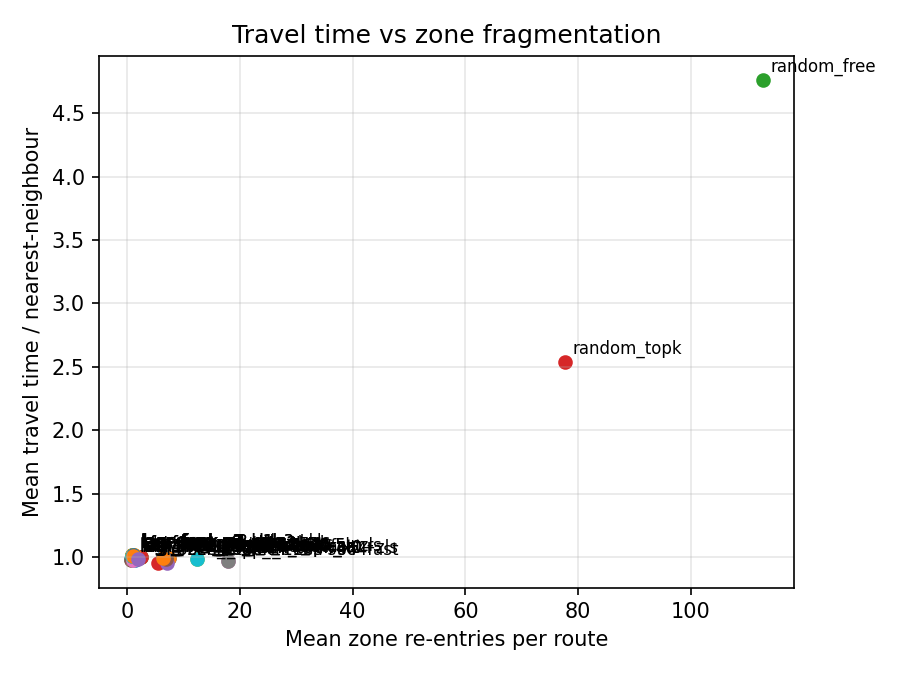

### test_perturb

| label | split | perturb | seeds | routes | mean_time_min | ratio_vs_driver | ratio_vs_nn | ratio_vs_nn_2opt | ratio_vs_ortools | mean_zone_exit | mean_zone_reentry | mean_far_jump | mean_pass_by | satisfied_zone_exit | satisfied_zone_reentry | satisfied_far_jump | satisfied_pass_by | share_time_le_driver | share_costs_le_driver | share_both_le_driver | nn_mean_zone_reentry | nn_mean_pass_by | nn_2opt_mean_zone_reentry | nn_2opt_mean_pass_by | ortools_mean_zone_reentry | ortools_mean_pass_by | amazon_score | amazon_score_nn | amazon_score_nn_2opt | amazon_score_ortools | mean_latency_ms | p_vs_driver | p_vs_nn | p_vs_nn_2opt | p_vs_ortools | p_vs_frozen_topk |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| frozen_topk | test | 0.2 | 3 | 461 | 168.8654 ± 0.7306 | 1.0050 ± 0.0043 | 0.9918 ± 0.0042 | 1.0495 ± 0.0044 | 1.1185 ± 0.0047 | 3.8934 ± 0.4127 | 7.3037 ± 0.7054 | 0.0007 ± 0.0010 | 1.3300 ± 0.0190 | 0.1020 ± 0.0226 | 0.0846 ± 0.0134 | 0.9993 ± 0.0010 | 1.0000 ± 0.0000 | 0.4852 ± 0.0211 | 0.0730 ± 0.0133 | 0.0412 ± 0.0031 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0762 ± 0.0013 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 637.1418 ± 162.9033 | 0.011895939481578223 | 1.329311777187525e-08 | 4.538480741173065e-62 | 3.0367014528848815e-77 |  |
| frozen_topk+zls | test | 0.2 | 3 | 461 | 168.8106 ± 0.7297 | 1.0046 ± 0.0043 | 0.9913 ± 0.0042 | 1.0490 ± 0.0045 | 1.1180 ± 0.0047 | 3.8934 ± 0.4127 | 7.3037 ± 0.7054 | 0.0007 ± 0.0010 | 1.3300 ± 0.0190 | 0.1020 ± 0.0226 | 0.0846 ± 0.0134 | 0.9993 ± 0.0010 | 1.0000 ± 0.0000 | 0.4859 ± 0.0215 | 0.0730 ± 0.0133 | 0.0412 ± 0.0031 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0762 ± 0.0013 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 653.3158 ± 166.8520 | 0.01621214364156546 | 3.834011059379093e-09 | 2.0460391556910277e-61 | 3.0367014528848815e-77 | 0.00014125368757832353 |
| lagr_free_p3 | test | 0.2 | 3 | 461 | 171.9427 ± 0.7966 | 1.0250 ± 0.0043 | 1.0122 ± 0.0041 | 1.0709 ± 0.0044 | 1.1414 ± 0.0048 | 0.4349 ± 0.0185 | 0.9226 ± 0.0288 | 0.0152 ± 0.0094 | 1.8327 ± 0.0918 | 0.7578 ± 0.0072 | 0.7672 ± 0.0037 | 0.9935 ± 0.0018 | 0.9986 ± 0.0010 | 0.3594 ± 0.0220 | 0.7411 ± 0.0102 | 0.2523 ± 0.0087 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0634 ± 0.0004 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 630.3336 ± 170.7658 | 2.690137559784542e-16 | 0.002152589724859974 | 1.307825432644028e-70 | 3.0765507769810147e-77 | 4.1788896349555134e-23 |
| lagr_free_p3+zls | test | 0.2 | 3 | 461 | 171.8364 ± 0.7786 | 1.0242 ± 0.0041 | 1.0113 ± 0.0040 | 1.0699 ± 0.0043 | 1.1404 ± 0.0046 | 0.4349 ± 0.0185 | 0.9226 ± 0.0288 | 0.0152 ± 0.0094 | 1.8292 ± 0.0907 | 0.7578 ± 0.0072 | 0.7672 ± 0.0037 | 0.9935 ± 0.0018 | 0.9986 ± 0.0010 | 0.3615 ± 0.0221 | 0.7411 ± 0.0102 | 0.2545 ± 0.0087 | 21.7939 ± 0.0000 | 1.4247 ± 0.0000 | 20.0954 ± 0.0000 | 3.4729 ± 0.0000 | 18.4078 ± 0.0000 | 3.5206 ± 0.0000 | 0.0634 ± 0.0004 | 0.1020 ± 0.0000 | 0.0952 ± 0.0000 | 0.0836 ± 0.0000 | 647.7470 ± 175.7362 | 1.2776185617224734e-15 | 0.0049577299085912995 | 2.085576508606399e-70 | 3.0765507769810147e-77 | 5.800248546789992e-22 |


In [ ]:
from pathlib import Path
from IPython.display import Markdown, Image, display

rep = Path(WORK_DIR) / f"report_{PRESET}_{SPLIT_BY}"
for sub in ("test", "test_perturb"):
    md_path = rep / sub / "report.md"
    if md_path.exists():
        display(Markdown(f"### {sub}"))
        display(Markdown(md_path.read_text()))
    png = rep / sub / "pareto.png"
    if png.exists():
        display(Image(str(png)))